<div style="background:#3D6F0C;color:white;padding:18px 22px;border-radius:10px;border-left:10px solid #F9C22E">
<h1 style="color:white;margin:0">Notebook Hasil Laporan – BAB III dan BAB IV</h1>
<p style="margin:6px 0 0 0">Klasifikasi Tumor Payudara Menggunakan <i>Random Forest</i> dan <i>Support Vector Machine</i> dengan Interpretasi SHAP</p>
</div>

Notebook ini menghasilkan **semua gambar dan tabel** yang dibutuhkan di BAB III dan BAB IV laporan. Urutannya mengikuti nomor subbab di laporan, jadi setiap anggota kelompok bisa langsung mencari bagiannya.

**Cara menjalankan**

1. Buka notebook ini dari folder utama proyek (folder yang berisi `train.py`).
2. Aktifkan *virtual environment*, lalu pilih kernel `.venv`.
3. Klik **Run All**. Seluruh proses (EDA, *preprocessing*, pelatihan, *K-Fold*, SHAP) selesai sekitar 1–2 menit.

**Hasil yang disimpan**

| Folder | Isi |
|---|---|
| `hasil_laporan/gambar/` | Semua gambar (PNG, 200 dpi) dengan nama file sesuai nomor gambar |
| `hasil_laporan/tabel/` | Semua tabel (CSV) dengan nama file sesuai nomor tabel |

**Catatan penomoran**

- Nomor gambar dan tabel **BAB IV** sudah mengikuti struktur final laporan.
- Nomor gambar dan tabel **BAB III** ditulis `3.x` karena urutannya bergantung pada bagian lain BAB III. Sesuaikan saat laporan digabung.
- Seluruh perhitungan memakai modul yang sama dengan `train.py` dan `app.py`, jadi angka di notebook ini sama dengan angka di aplikasi.

### Pembagian bagian laporan

| Subbab | Isi di notebook ini | Penanggung jawab |
|---|---|---|
| 3.1, 3.2, 4.1 | Alur CRISP-DM, Tabel 4.1 *Business Understanding* | Ananta |
| 3.3, 4.2 | Ringkasan dan deskripsi dataset, hasil EDA (Gambar 4.1–4.6, Tabel 4.2–4.5) | Yosua |
| 3.4, 4.3 | Alur *Data Preparation*, Tabel 4.6–4.8 | Gekani |
| 3.5, 4.4 | Hasil pelatihan model (Tabel 4.9–4.10) | Yosua |
| 3.6, 4.5 | Skema *K-Fold*, *confusion matrix*, metrik, *feature importance*, SHAP (Gambar 4.7–4.13, Tabel 4.11–4.14) | Gekani |
| 3.7, 4.6 | Struktur basis data (Gambar 4.14), templat *Blackbox* (Tabel 4.15) | Ananta |
| 4.7 | Perbandingan penelitian terdahulu (Tabel 4.16) | Gekani |

---
## 0. Persiapan

Sel ini memuat modul proyek, mengatur warna **grafik** (hijau–kuning, sama seperti tema PPT), dan menyiapkan fungsi untuk menyimpan gambar dan tabel. Tabel ditampilkan polos tanpa warna.

| Warna | Kode | Dipakai untuk |
|---|---|---|
| <span style="background:#3D6F0C;color:white;padding:2px 8px">Hijau</span> | `#3D6F0C` | kelas *Benign*, model *Random Forest*, prediksi benar |
| <span style="background:#F9C22E;padding:2px 8px">Kuning</span> | `#F9C22E` | kelas *Malignant*, model SVM, *False Negative*, nilai penting |
| <span style="background:#003D06;color:white;padding:2px 8px">Hijau tua</span> | `#003D06` | judul dan garis |
| <span style="background:#B9D19F;padding:2px 8px">Hijau muda</span> | `#B9D19F` | data latih, latar pendukung |

In [1]:
import warnings
warnings.filterwarnings("ignore")
import re, time, sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Circle
from IPython.display import display, Markdown

# Modul proyek (sama dengan train.py dan app.py)
from preprocessing import data as prep, eda
from random_forest.rf_manual import RandomForestManual
from random_forest import feature_importance as fi
from svm.svm_manual import SVMManual
from evaluasi import metrik as ev
from interpretasi_shap import shap_svm
from basis_data import database as db
import shap

pd.set_option("display.max_rows", 100)

In [2]:
# Beberapa modul memakai backend tanpa layar (untuk train.py); kembalikan ke tampilan notebook
%matplotlib inline

# ---------- Palet warna (tema PPT) ----------
HIJAU, HIJAU_TUA, HIJAU_MUDA, KREM = "#3D6F0C", "#003D06", "#B9D19F", "#F1F5EC"
KUNING, KUNING_TUA, TEKS, ABU = "#F9C22E", "#B8860B", "#2E3A2F", "#7C8B72"
WARNA_KELAS = {"Benign": HIJAU, "Malignant": KUNING}
WARNA_MODEL = {"Random Forest": HIJAU, "SVM": KUNING}
CMAP_HIJAU = LinearSegmentedColormap.from_list("hijau", [KREM, HIJAU_MUDA, HIJAU, HIJAU_TUA])
CMAP_KORELASI = LinearSegmentedColormap.from_list("korelasi", [KUNING, "#FFFFFF", HIJAU_MUDA, HIJAU, HIJAU_TUA])
CMAP_SHAP = LinearSegmentedColormap.from_list("shap", [HIJAU, "#A8C256", KUNING])

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
    "axes.edgecolor": ABU, "axes.labelcolor": TEKS, "xtick.color": TEKS, "ytick.color": TEKS,
    "axes.titleweight": "bold", "axes.titlecolor": HIJAU_TUA, "axes.titlesize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#E3E9DC", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False,
})

OUT = Path("hasil_laporan")
(OUT / "gambar").mkdir(parents=True, exist_ok=True)
(OUT / "tabel").mkdir(parents=True, exist_ok=True)

def _nama_file(nomor, judul):
    return re.sub(r"[^0-9A-Za-z.]+", "_", f"{nomor} {judul}").strip("_")

def simpan_gambar(fig, nomor, judul):
    # Menyimpan gambar ke hasil_laporan/gambar dan menampilkan keterangan gambar
    nama = _nama_file(nomor, judul) + ".png"
    fig.savefig(OUT / "gambar" / nama, bbox_inches="tight", facecolor="white")
    plt.show()
    display(Markdown(f"<p style='text-align:center'><b>{nomor}</b> {judul}<br><code>hasil_laporan/gambar/{nama}</code></p>"))

def angka(x, d=4):
    # Format angka Indonesia: koma desimal, titik ribuan
    if isinstance(x, str):
        return x
    return f"{x:,.{d}f}".replace(",", "#").replace(".", ",").replace("#", ".")

def persen(x, d=2):
    return angka(x * 100, d) + "%"

def tampil_tabel(df, nomor, judul, tampil=None):
    # Menyimpan tabel ke CSV dan menampilkannya (tanpa warna)
    nama = _nama_file(nomor, judul) + ".csv"
    df.to_csv(OUT / "tabel" / nama, index=False)
    display(Markdown(f"<p style='text-align:center'><b>{nomor}</b> {judul}</p>"))
    d = df if tampil is None else df.head(tampil)
    display(d.style.hide(axis="index").set_properties(**{"text-align": "left"}))
    keterangan = f"`hasil_laporan/tabel/{nama}`"
    if tampil is not None and len(df) > tampil:
        keterangan += f" (ditampilkan {tampil} dari {len(df)} baris, CSV berisi semua baris)"
    display(Markdown(keterangan))

def kotak(ax, x, y, w, h, teks, warna=HIJAU, warna_teks="white", ukuran=9, tebal=True):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.02,rounding_size=0.12",
                                facecolor=warna, edgecolor=HIJAU_TUA, linewidth=1.2))
    ax.text(x, y, teks, ha="center", va="center", color=warna_teks, fontsize=ukuran,
            fontweight="bold" if tebal else "normal", wrap=True)

def panah(ax, a, b, rad=0.0, warna=HIJAU_TUA, gaya="-|>", garis="-"):
    ax.add_patch(FancyArrowPatch(a, b, arrowstyle=gaya, mutation_scale=14, color=warna, linewidth=1.4,
                                 linestyle=garis, connectionstyle=f"arc3,rad={rad}"))

print("Persiapan selesai. Output disimpan di:", OUT.resolve())

Persiapan selesai. Output disimpan di: /tmp/claude-0/-home-claude/5b81c91e-3a72-56cd-a49b-1dfee1c8ec2a/scratchpad/pda/hasil_laporan


---
# BAB III – ANALISIS DAN DESAIN SISTEM

Bagian ini berisi gambar dan tabel pendukung rancangan. Flowchart algoritma (pelatihan model, *Random Forest*, SVM, SHAP), DFD, ERD, dan desain antarmuka tetap memakai gambar draw.io yang sudah ada di laporan.

## 3.1 Tahapan Penelitian (Alur CRISP-DM)

Gambar alur enam fase CRISP-DM (Shimaoka dkk., 2024). Di bawah setiap fase dicantumkan subbab rancangan (BAB III) dan subbab hasilnya (BAB IV), sehingga pembaca bisa melihat keterkaitan kedua bab.

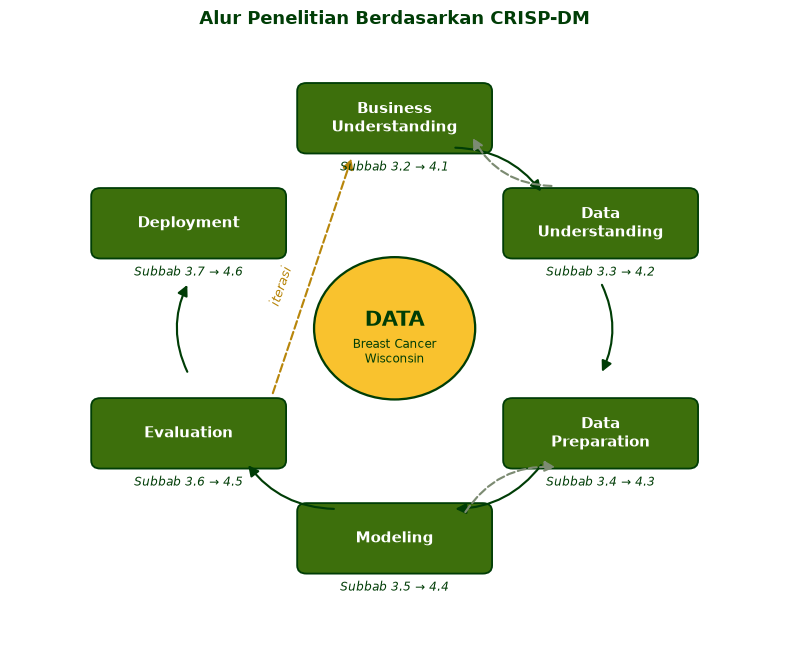

<p style='text-align:center'><b>Gambar 3.x</b> Alur Tahapan Penelitian CRISP-DM<br><code>hasil_laporan/gambar/Gambar_3.x_Alur_Tahapan_Penelitian_CRISP_DM.png</code></p>

In [3]:
fig, ax = plt.subplots(figsize=(9, 7.2))
ax.set_xlim(-5, 5); ax.set_ylim(-4.6, 4.4); ax.axis("off"); ax.grid(False)

fase = [("Business\nUnderstanding", "3.2 → 4.1"), ("Data\nUnderstanding", "3.3 → 4.2"),
        ("Data\nPreparation", "3.4 → 4.3"), ("Modeling", "3.5 → 4.4"),
        ("Evaluation", "3.6 → 4.5"), ("Deployment", "3.7 → 4.6")]
sudut = np.deg2rad([90, 30, -30, -90, -150, 150])
R = 3.1
pos = [(R * np.cos(s), R * np.sin(s)) for s in sudut]

ax.add_patch(Circle((0, 0), 1.05, facecolor=KUNING, edgecolor=HIJAU_TUA, linewidth=1.5))
ax.text(0, 0.12, "DATA", ha="center", va="center", fontsize=14, fontweight="bold", color=HIJAU_TUA)
ax.text(0, -0.35, "Breast Cancer\nWisconsin", ha="center", va="center", fontsize=8, color=HIJAU_TUA)

for (nama, sub), (x, y) in zip(fase, pos):
    kotak(ax, x, y, 2.5, 1.0, nama, warna=HIJAU, ukuran=10)
    ax.text(x, y - 0.72, f"Subbab {sub}", ha="center", va="center", fontsize=8, color=HIJAU_TUA, style="italic")

for i in range(5):
    (x1, y1), (x2, y2) = pos[i], pos[i + 1]
    panah(ax, (x1 + (x2 - x1) * 0.28, y1 + (y2 - y1) * 0.28), (x1 + (x2 - x1) * 0.72, y1 + (y2 - y1) * 0.72), rad=-0.25)
# umpan balik
panah(ax, (pos[1][0] - 0.6, pos[1][1] + 0.55), (pos[0][0] + 1.0, pos[0][1] - 0.25), rad=-0.3, warna=ABU, garis="--")
panah(ax, (pos[3][0] + 0.9, pos[3][1] + 0.35), (pos[2][0] - 0.55, pos[2][1] - 0.5), rad=-0.3, warna=ABU, garis="--")
panah(ax, (-1.6, -1.0), (-0.55, 2.55), rad=0.0, warna=KUNING_TUA, garis="--")
ax.text(-1.48, 0.62, "iterasi", fontsize=8.5, color=KUNING_TUA, style="italic", rotation=71, ha="center", va="center")
ax.set_title("Alur Penelitian Berdasarkan CRISP-DM", pad=4)
simpan_gambar(fig, "Gambar 3.x", "Alur Tahapan Penelitian CRISP-DM")

## 3.3 *Data Understanding*

### 3.3.1–3.3.2 Sumber dan Deskripsi Dataset
Ringkasan dataset dan arti setiap karakteristik inti sel. Setiap karakteristik memiliki tiga variasi, yaitu `mean` (rata-rata), `se` (*standard error*), dan `worst` (rata-rata tiga nilai terbesar), sehingga totalnya 30 fitur. Seluruh 30 fitur ini digunakan sebagai variabel prediktor.

In [4]:
df = prep.muat_dataset()
dist = df["diagnosis"].value_counts()

ringkasan_dataset = pd.DataFrame({
    "Keterangan": ["Nama dataset", "Sumber", "Jumlah data", "Jumlah kolom", "Kolom identitas",
                   "Kolom target", "Jumlah fitur", "Jenis fitur"],
    "Nilai": ["Breast Cancer Wisconsin (Diagnostic)", "UCI Machine Learning Repository (doi:10.24432/C5DW2B)",
              f"{len(df)} pasien", f"{df.shape[1]} kolom", "id",
              f"diagnosis: M = malignant ({dist['M']}), B = benign ({dist['B']})",
              "30 fitur (10 karakteristik × 3 variasi)", "Numerik kontinu, hasil pengukuran citra FNA"],
})
tampil_tabel(ringkasan_dataset, "Tabel 3.x", "Ringkasan Dataset")

arti = {
    "radius": "Rata-rata jarak dari pusat ke titik-titik keliling inti sel",
    "texture": "Standar deviasi nilai skala abu-abu (gray-scale)",
    "perimeter": "Keliling inti sel",
    "area": "Luas inti sel",
    "smoothness": "Variasi lokal panjang radius",
    "compactness": "Kepadatan bentuk, perimeter² / area − 1,0",
    "concavity": "Tingkat kedalaman bagian cekung pada kontur",
    "concave_points": "Jumlah bagian cekung pada kontur",
    "symmetry": "Kesimetrisan inti sel",
    "fractal_dimension": "Kerumitan kontur (coastline approximation − 1)",
}
deskripsi = pd.DataFrame({
    "No": range(1, 11),
    "Karakteristik": [prep.NAMA_KARAKTERISTIK[k] for k in prep.KARAKTERISTIK],
    "Keterangan": [arti[k] for k in prep.KARAKTERISTIK],
    "Nama Fitur": [f"{k}_mean, {k}_se, {k}_worst" for k in prep.KARAKTERISTIK],
})
tampil_tabel(deskripsi, "Tabel 3.x", "Deskripsi Fitur Dataset")

<p style='text-align:center'><b>Tabel 3.x</b> Ringkasan Dataset</p>

Keterangan,Nilai
Nama dataset,Breast Cancer Wisconsin (Diagnostic)
Sumber,UCI Machine Learning Repository (doi:10.24432/C5DW2B)
Jumlah data,569 pasien
Jumlah kolom,32 kolom
Kolom identitas,id
Kolom target,"diagnosis: M = malignant (212), B = benign (357)"
Jumlah fitur,30 fitur (10 karakteristik × 3 variasi)
Jenis fitur,"Numerik kontinu, hasil pengukuran citra FNA"


`hasil_laporan/tabel/Tabel_3.x_Ringkasan_Dataset.csv`

<p style='text-align:center'><b>Tabel 3.x</b> Deskripsi Fitur Dataset</p>

No,Karakteristik,Keterangan,Nama Fitur
1,Radius,Rata-rata jarak dari pusat ke titik-titik keliling inti sel,"radius_mean, radius_se, radius_worst"
2,Texture,Standar deviasi nilai skala abu-abu (gray-scale),"texture_mean, texture_se, texture_worst"
3,Perimeter,Keliling inti sel,"perimeter_mean, perimeter_se, perimeter_worst"
4,Area,Luas inti sel,"area_mean, area_se, area_worst"
5,Smoothness,Variasi lokal panjang radius,"smoothness_mean, smoothness_se, smoothness_worst"
6,Compactness,"Kepadatan bentuk, perimeter² / area − 1,0","compactness_mean, compactness_se, compactness_worst"
7,Concavity,Tingkat kedalaman bagian cekung pada kontur,"concavity_mean, concavity_se, concavity_worst"
8,Concave points,Jumlah bagian cekung pada kontur,"concave_points_mean, concave_points_se, concave_points_worst"
9,Symmetry,Kesimetrisan inti sel,"symmetry_mean, symmetry_se, symmetry_worst"
10,Fractal dimension,Kerumitan kontur (coastline approximation − 1),"fractal_dimension_mean, fractal_dimension_se, fractal_dimension_worst"


`hasil_laporan/tabel/Tabel_3.x_Deskripsi_Fitur_Dataset.csv`

## 3.4 *Data Preparation*

Urutan langkah *data preparation* yang dirancang berdasarkan temuan EDA. Langkah dengan garis kuning (imputasi dan *z-score*) dihitung **hanya dari data latih** untuk mencegah *data leakage*.

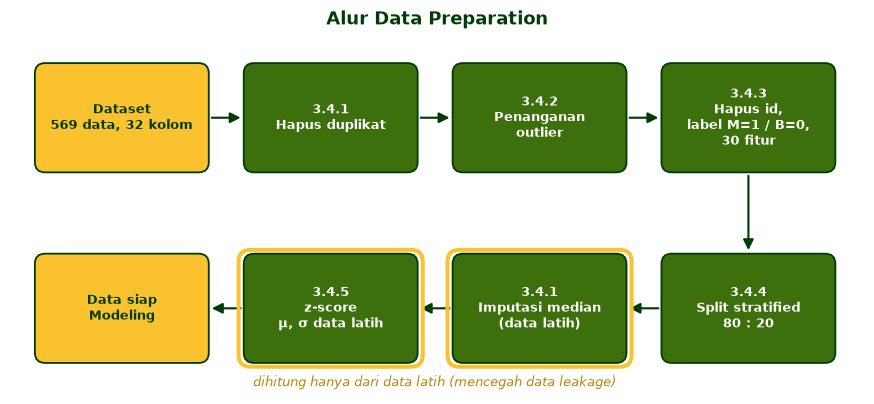

<p style='text-align:center'><b>Gambar 3.x</b> Alur Data Preparation<br><code>hasil_laporan/gambar/Gambar_3.x_Alur_Data_Preparation.png</code></p>

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.3))
ax.set_xlim(0, 10); ax.set_ylim(0, 4.3); ax.axis("off"); ax.grid(False)

baris1 = [("Dataset\n569 data, 32 kolom", KUNING, HIJAU_TUA), ("3.4.1\nHapus duplikat", HIJAU, "white"),
          ("3.4.2\nPenanganan\noutlier", HIJAU, "white"), ("3.4.3\nHapus id,\nlabel M=1 / B=0,\n30 fitur", HIJAU, "white")]
baris2 = [("3.4.4\nSplit stratified\n80 : 20", HIJAU, "white"), ("3.4.1\nImputasi median\n(data latih)", HIJAU, "white"),
          ("3.4.5\nz-score\nμ, σ data latih", HIJAU, "white"), ("Data siap\nModeling", KUNING, HIJAU_TUA)]
xs = [1.3, 3.75, 6.2, 8.65]
xs2 = xs[::-1]                      # baris kedua berjalan dari kanan ke kiri
for (t, w, c), x in zip(baris1, xs):
    kotak(ax, x, 3.25, 2.0, 1.25, t, warna=w, warna_teks=c, ukuran=8.5)
for (t, w, c), x in zip(baris2, xs2):
    kotak(ax, x, 1.0, 2.0, 1.25, t, warna=w, warna_teks=c, ukuran=8.5)
for i in range(3):
    panah(ax, (xs[i] + 1.02, 3.25), (xs[i + 1] - 1.02, 3.25))
    panah(ax, (xs2[i] - 1.02, 1.0), (xs2[i + 1] + 1.02, 1.0))
panah(ax, (xs[3], 2.6), (xs[3], 1.65))
for x in (xs2[1], xs2[2]):
    ax.add_patch(FancyBboxPatch((x - 1.06, 0.33), 2.12, 1.34, boxstyle="round,pad=0.02,rounding_size=0.14",
                                facecolor="none", edgecolor=KUNING, linewidth=2.6))
ax.text(4.97, 0.08, "dihitung hanya dari data latih (mencegah data leakage)", ha="center", fontsize=8.5,
        color=KUNING_TUA, style="italic")
ax.set_title("Alur Data Preparation", pad=2)
simpan_gambar(fig, "Gambar 3.x", "Alur Data Preparation")

## 3.6 *Evaluation*

### 3.6.1 Desain Validasi: *Stratified K-Fold Cross Validation*
Skema satu kali ulangan *Stratified* 10-*Fold*. Setiap baris adalah satu iterasi: *fold* kuning menjadi data uji dan *fold* hijau muda menjadi data latih. Skema ini diulang 5 kali dengan pengacakan berbeda sehingga setiap model diuji 50 kali.

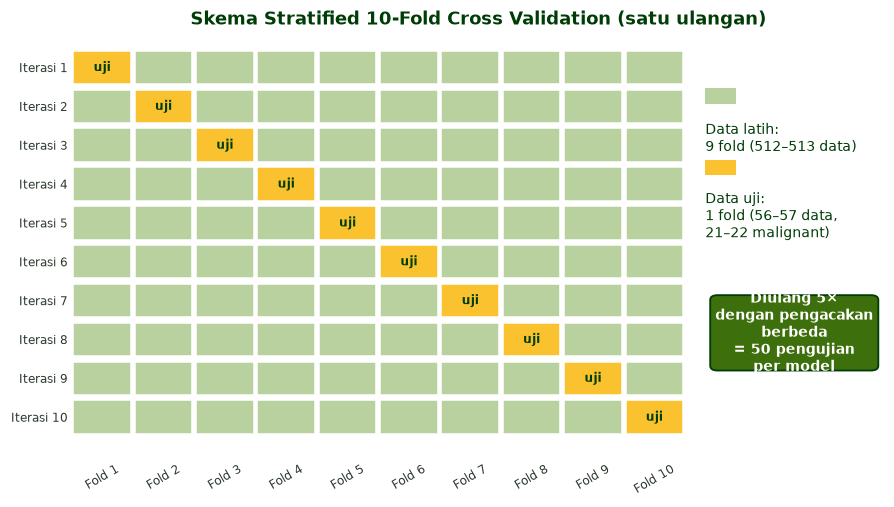

<p style='text-align:center'><b>Gambar 3.x</b> Skema Stratified 10-Fold Cross Validation<br><code>hasil_laporan/gambar/Gambar_3.x_Skema_Stratified_10_Fold_Cross_Validation.png</code></p>

In [6]:
fig, ax = plt.subplots(figsize=(9.5, 5))
ax.grid(False)
for i in range(10):
    for j in range(10):
        uji = i == j
        ax.add_patch(plt.Rectangle((j, 9 - i), 0.94, 0.86, facecolor=KUNING if uji else HIJAU_MUDA,
                                   edgecolor="white"))
        if uji:
            ax.text(j + 0.47, 9 - i + 0.43, "uji", ha="center", va="center", fontsize=8, color=HIJAU_TUA, fontweight="bold")
ax.set_xlim(0, 13.2); ax.set_ylim(-0.6, 10.3)
ax.set_xticks(np.arange(10) + 0.47); ax.set_xticklabels([f"Fold {k}" for k in range(1, 11)], fontsize=8, rotation=30)
ax.set_yticks(np.arange(10) + 0.43); ax.set_yticklabels([f"Iterasi {k}" for k in range(10, 0, -1)], fontsize=8)
ax.spines[["left", "bottom"]].set_visible(False); ax.tick_params(length=0)
ax.text(10.3, 7.6, "Data latih:\n9 fold (512–513 data)", fontsize=9, color=HIJAU_TUA, va="center")
ax.add_patch(plt.Rectangle((10.3, 8.5), 0.5, 0.4, facecolor=HIJAU_MUDA))
ax.text(10.3, 5.6, "Data uji:\n1 fold (56–57 data,\n21–22 malignant)", fontsize=9, color=HIJAU_TUA, va="center")
ax.add_patch(plt.Rectangle((10.3, 6.65), 0.5, 0.4, facecolor=KUNING))
kotak(ax, 11.75, 2.6, 2.7, 1.9, "Diulang 5×\ndengan pengacakan\nberbeda\n= 50 pengujian\nper model", warna=HIJAU, ukuran=9)
ax.set_title("Skema Stratified 10-Fold Cross Validation (satu ulangan)", pad=6)
simpan_gambar(fig, "Gambar 3.x", "Skema Stratified 10-Fold Cross Validation")

---
# BAB IV – HASIL DAN PEMBAHASAN

## 4.1 Hasil *Business Understanding*
Tabel ringkas tujuan dan kriteria keberhasilan. Kriteria ini dipakai kembali di Subbab 4.7 untuk menilai hasil.

In [7]:
bu = pd.DataFrame({
    "Aspek": ["Tujuan bisnis", "Pengguna sistem", "Tujuan data mining", "Kriteria keberhasilan model",
              "Kriteria keberhasilan sistem", "Keterkaitan rumusan masalah"],
    "Hasil": ["Membantu tenaga medis membedakan tumor malignant dan benign beserta alasan prediksinya",
              "Tenaga medis (dokter spesialis patologi anatomi dan petugas laboratorium patologi)",
              "Klasifikasi biner dengan Random Forest dan SVM, interpretasi feature importance dan SHAP",
              "Recall diprioritaskan agar False Negative sekecil mungkin; F1-score sebagai pembanding kedua",
              "Seluruh skenario Blackbox Testing berjalan sesuai hasil yang diharapkan",
              "RM 1 → 4.5.1–4.5.3; RM 2 → 4.5.4; RM 3 → 4.6"],
})
tampil_tabel(bu, "Tabel 4.1", "Hasil Business Understanding")

<p style='text-align:center'><b>Tabel 4.1</b> Hasil Business Understanding</p>

Aspek,Hasil
Tujuan bisnis,Membantu tenaga medis membedakan tumor malignant dan benign beserta alasan prediksinya
Pengguna sistem,Tenaga medis (dokter spesialis patologi anatomi dan petugas laboratorium patologi)
Tujuan data mining,"Klasifikasi biner dengan Random Forest dan SVM, interpretasi feature importance dan SHAP"
Kriteria keberhasilan model,Recall diprioritaskan agar False Negative sekecil mungkin; F1-score sebagai pembanding kedua
Kriteria keberhasilan sistem,Seluruh skenario Blackbox Testing berjalan sesuai hasil yang diharapkan
Keterkaitan rumusan masalah,RM 1 → 4.5.1–4.5.3; RM 2 → 4.5.4; RM 3 → 4.6


`hasil_laporan/tabel/Tabel_4.1_Hasil_Business_Understanding.csv`

## 4.2 Hasil *Data Understanding*
Seluruh hasil EDA dihitung dengan modul `preprocessing/eda.py`, sama dengan yang ditampilkan di halaman **Tentang Data** pada aplikasi.

### 4.2.1 Hasil Pemeriksaan Kualitas Data

In [8]:
df = prep.muat_dataset()
hasil_eda = eda.jalankan_eda(df)          # tanpa folder → tidak membuat grafik bawaan
q = hasil_eda["kualitas"]
kualitas = pd.DataFrame({
    "Pemeriksaan": ["Jumlah data", "Jumlah kolom", "Fitur numerik", "Missing value", "Data duplikat (tanpa kolom id)",
                    "Nomor id ganda", "Nilai negatif pada fitur", "Label unik"],
    "Hasil": [q["jumlah_data"], q["jumlah_kolom"], q["fitur_numerik"], q["missing_value"], q["duplikat"],
              q["id_duplikat"], q["nilai_negatif"], ", ".join(q["label_unik"])],
})
tampil_tabel(kualitas, "Tabel 4.2", "Hasil Pemeriksaan Kualitas Data")

<p style='text-align:center'><b>Tabel 4.2</b> Hasil Pemeriksaan Kualitas Data</p>

Pemeriksaan,Hasil
Jumlah data,569
Jumlah kolom,32
Fitur numerik,30
Missing value,0
Data duplikat (tanpa kolom id),0
Nomor id ganda,0
Nilai negatif pada fitur,0
Label unik,"B, M"


`hasil_laporan/tabel/Tabel_4.2_Hasil_Pemeriksaan_Kualitas_Data.csv`

### 4.2.2 Hasil Distribusi Kelas

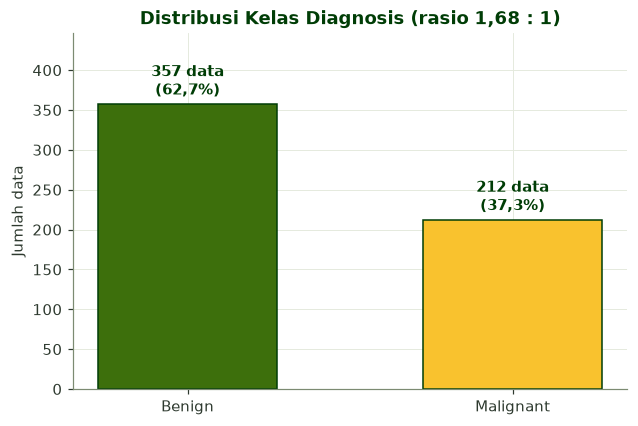

<p style='text-align:center'><b>Gambar 4.1</b> Distribusi Kelas Malignant dan Benign<br><code>hasil_laporan/gambar/Gambar_4.1_Distribusi_Kelas_Malignant_dan_Benign.png</code></p>

In [9]:
d = hasil_eda["distribusi_kelas"]
fig, ax = plt.subplots(figsize=(6.5, 4.2))
kelas = ["Benign", "Malignant"]; nilai = [d["benign"], d["malignant"]]; pr = [d["persen_benign"], d["persen_malignant"]]
bar = ax.bar(kelas, nilai, color=[WARNA_KELAS[k] for k in kelas], edgecolor=HIJAU_TUA, width=0.55)
for b, n, p in zip(bar, nilai, pr):
    ax.text(b.get_x() + b.get_width() / 2, n + 6, f"{n} data\n({angka(p, 1)}%)", ha="center", va="bottom",
            fontweight="bold", color=HIJAU_TUA)
ax.set_ylim(0, max(nilai) * 1.25); ax.set_ylabel("Jumlah data")
ax.set_title(f"Distribusi Kelas Diagnosis (rasio {angka(d['rasio_mayoritas_minoritas'], 2)} : 1)")
simpan_gambar(fig, "Gambar 4.1", "Distribusi Kelas Malignant dan Benign")

### 4.2.3 Hasil Statistik Deskriptif dan Skala Fitur

In [10]:
stat = eda.statistik_deskriptif(df)
tabel_stat = pd.DataFrame({
    "Fitur": stat.index,
    "Min": [angka(v) for v in stat["min"]], "Maks": [angka(v) for v in stat["max"]],
    "Rata-rata": [angka(v) for v in stat["mean"]], "Median": [angka(v) for v in stat["median"]],
    "Std": [angka(v) for v in stat["std"]],
})
tampil_tabel(tabel_stat, "Tabel 4.3", "Statistik Deskriptif Fitur")

<p style='text-align:center'><b>Tabel 4.3</b> Statistik Deskriptif Fitur</p>

Fitur,Min,Maks,Rata-rata,Median,Std
radius_mean,"6,9810","28,1100","14,1273","13,3700","3,5240"
texture_mean,"9,7100","39,2800","19,2896","18,8400","4,3010"
perimeter_mean,"43,7900","188,5000","91,9690","86,2400","24,2990"
area_mean,"143,5000","2.501,0000","654,8891","551,1000","351,9141"
smoothness_mean,"0,0526","0,1634","0,0964","0,0959","0,0141"
compactness_mean,"0,0194","0,3454","0,1043","0,0926","0,0528"
concavity_mean,"0,0000","0,4268","0,0888","0,0615","0,0797"
concave_points_mean,"0,0000","0,2012","0,0489","0,0335","0,0388"
symmetry_mean,"0,1060","0,3040","0,1812","0,1792","0,0274"
fractal_dimension_mean,"0,0500","0,0974","0,0628","0,0615","0,0071"


`hasil_laporan/tabel/Tabel_4.3_Statistik_Deskriptif_Fitur.csv`

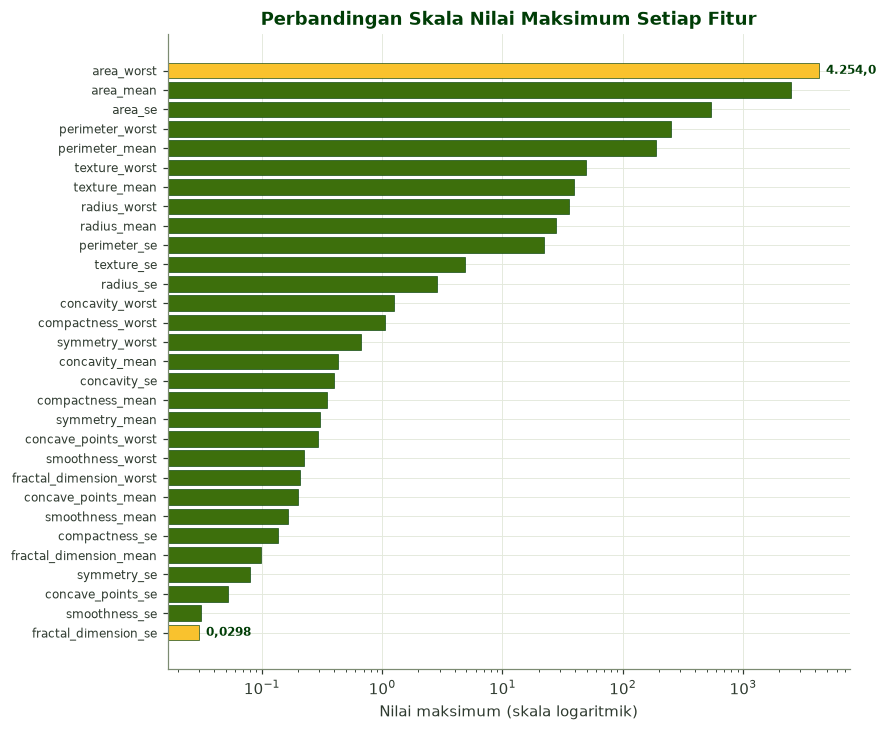

<p style='text-align:center'><b>Gambar 4.2</b> Perbandingan Skala Fitur<br><code>hasil_laporan/gambar/Gambar_4.2_Perbandingan_Skala_Fitur.png</code></p>

In [11]:
sk = hasil_eda["skala"]
urut = stat["max"].sort_values()
warna = [KUNING if f in (sk["fitur_nilai_terbesar"], sk["fitur_nilai_terkecil"]) else HIJAU for f in urut.index]
fig, ax = plt.subplots(figsize=(8, 7.5))
ax.barh(urut.index, urut.values, color=warna, edgecolor=HIJAU_TUA, linewidth=0.4)
ax.set_xscale("log"); ax.set_xlabel("Nilai maksimum (skala logaritmik)")
ax.tick_params(axis="y", labelsize=8)
for f in (sk["fitur_nilai_terbesar"], sk["fitur_nilai_terkecil"]):
    ax.text(urut[f] * 1.15, list(urut.index).index(f), angka(urut[f], 4 if urut[f] < 1 else 1), va="center", fontsize=8,
            fontweight="bold", color=HIJAU_TUA)
ax.set_title("Perbandingan Skala Nilai Maksimum Setiap Fitur")
simpan_gambar(fig, "Gambar 4.2", "Perbandingan Skala Fitur")

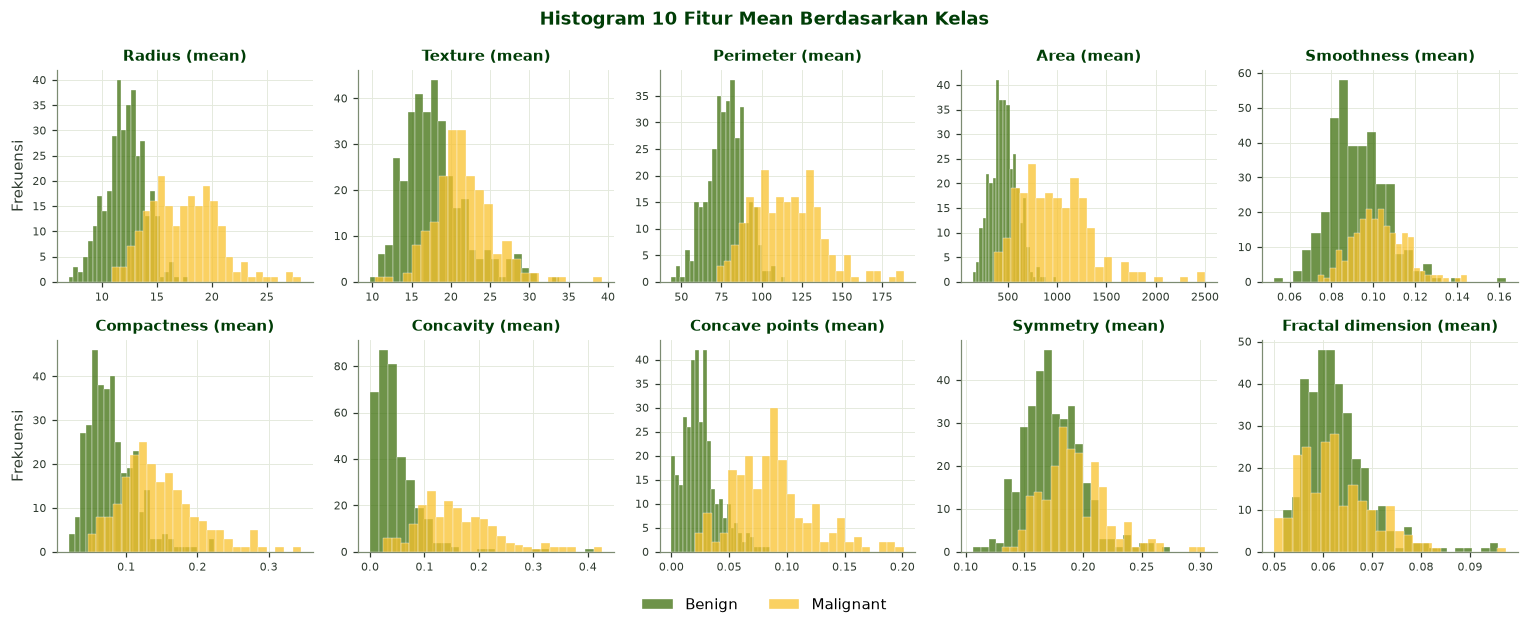

<p style='text-align:center'><b>Gambar 4.3</b> Histogram Fitur Mean<br><code>hasil_laporan/gambar/Gambar_4.3_Histogram_Fitur_Mean.png</code></p>

In [12]:
fitur_mean = [f"{k}_mean" for k in prep.KARAKTERISTIK]
fig, axes = plt.subplots(2, 5, figsize=(14, 5.6))
for ax, f in zip(axes.ravel(), fitur_mean):
    for kode, nama in (("B", "Benign"), ("M", "Malignant")):
        ax.hist(df.loc[df["diagnosis"] == kode, f], bins=25, alpha=0.75, color=WARNA_KELAS[nama],
                edgecolor="white", linewidth=0.3, label=nama)
    ax.set_title(prep.label_fitur(f), fontsize=9.5)
    ax.tick_params(labelsize=7)
axes[0, 0].set_ylabel("Frekuensi"); axes[1, 0].set_ylabel("Frekuensi")
fig.legend(["Benign", "Malignant"], loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("Histogram 10 Fitur Mean Berdasarkan Kelas", fontweight="bold", color=HIJAU_TUA)
fig.tight_layout(rect=(0, 0.04, 1, 1))
simpan_gambar(fig, "Gambar 4.3", "Histogram Fitur Mean")

### 4.2.4 Hasil Deteksi *Outlier*
*Outlier* dideteksi dengan metode IQR (nilai < Q1 − 1,5 IQR atau > Q3 + 1,5 IQR).

In [13]:
tabel_outlier, o = eda.deteksi_outlier(df)
tab_o = tabel_outlier.reset_index().rename(columns={"index": "Fitur"})
tab_o = pd.DataFrame({
    "Fitur": tab_o["Fitur"], "Batas Bawah": [angka(v) for v in tab_o["batas_bawah"]],
    "Batas Atas": [angka(v) for v in tab_o["batas_atas"]], "Jumlah Outlier": tab_o["jumlah_outlier"],
    "Persentase": [angka(v, 1) + "%" for v in tab_o["persen"]],
    "Malignant": tab_o["dari_malignant"], "Benign": tab_o["dari_benign"],
})
tampil_tabel(tab_o, "Tabel 4.4", "Jumlah Outlier per Fitur", tampil=10)
print(f"Total nilai outlier : {o['total_nilai_outlier']} dari {o['total_nilai']} nilai")
print(f"Pasien dengan outlier: {o['pasien_dengan_outlier']} ({o['pasien_outlier_malignant']} malignant, {o['pasien_outlier_benign']} benign)")
print(f"Nilai outlier dari malignant: {o['persen_nilai_outlier_dari_malignant']}%  |  di atas batas atas: {o['di_atas_batas_atas']}")

<p style='text-align:center'><b>Tabel 4.4</b> Jumlah Outlier per Fitur</p>

Fitur,Batas Bawah,Batas Atas,Jumlah Outlier,Persentase,Malignant,Benign
area_se,"-23,1600","86,2000",65,"11,4%",65,0
radius_se,"-0,1374","0,8487",38,"6,7%",37,1
perimeter_se,"-1,0205","5,9835",38,"6,7%",38,0
area_worst,"-337,7500","1.937,0500",35,"6,2%",35,0
smoothness_se,"0,0007","0,0126",30,"5,3%",4,26
fractal_dimension_se,"-0,0012","0,0080",28,"4,9%",10,18
compactness_se,"-0,0160","0,0615",28,"4,9%",14,14
symmetry_se,"0,0027","0,0360",27,"4,7%",16,11
area_mean,"-123,3000","1.326,3000",25,"4,4%",25,0
fractal_dimension_worst,"0,0405","0,1230",24,"4,2%",18,6


`hasil_laporan/tabel/Tabel_4.4_Jumlah_Outlier_per_Fitur.csv` (ditampilkan 10 dari 30 baris, CSV berisi semua baris)

Total nilai outlier : 608 dari 17070 nilai
Pasien dengan outlier: 171 (114 malignant, 57 benign)
Nilai outlier dari malignant: 77.1%  |  di atas batas atas: 605


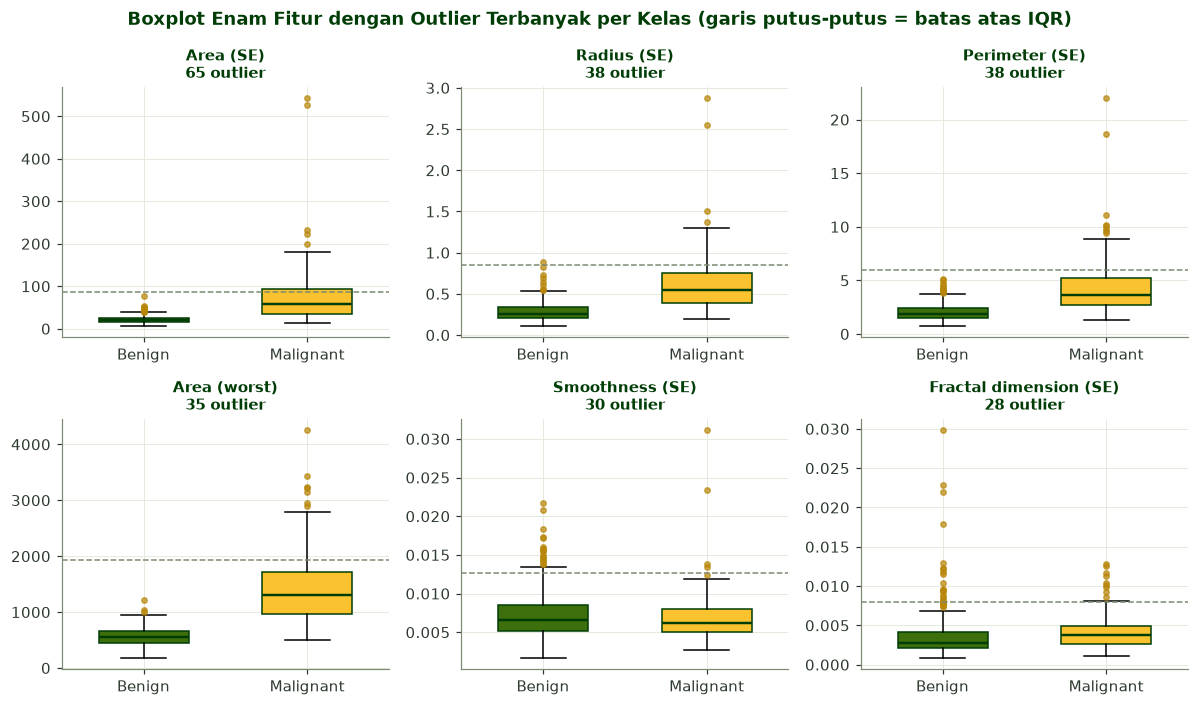

<p style='text-align:center'><b>Gambar 4.4</b> Boxplot Outlier per Kelas<br><code>hasil_laporan/gambar/Gambar_4.4_Boxplot_Outlier_per_Kelas.png</code></p>

In [14]:
top6 = tabel_outlier.index[:6]
fig, axes = plt.subplots(2, 3, figsize=(11, 6.5))
for ax, f in zip(axes.ravel(), top6):
    data = [df.loc[df["diagnosis"] == "B", f], df.loc[df["diagnosis"] == "M", f]]
    bp = ax.boxplot(data, patch_artist=True, widths=0.55, tick_labels=["Benign", "Malignant"],
                    medianprops=dict(color=HIJAU_TUA, linewidth=1.6),
                    flierprops=dict(marker="o", markersize=3.5, markerfacecolor=KUNING_TUA, markeredgecolor=KUNING_TUA, alpha=0.7))
    for p, w in zip(bp["boxes"], [HIJAU, KUNING]):
        p.set_facecolor(w); p.set_edgecolor(HIJAU_TUA)
    ax.axhline(tabel_outlier.loc[f, "batas_atas"], color=ABU, linestyle="--", linewidth=1)
    ax.set_title(f"{prep.label_fitur(f)}\n{int(tabel_outlier.loc[f, 'jumlah_outlier'])} outlier", fontsize=9.5)
fig.suptitle("Boxplot Enam Fitur dengan Outlier Terbanyak per Kelas (garis putus-putus = batas atas IQR)",
             fontweight="bold", color=HIJAU_TUA)
fig.tight_layout()
simpan_gambar(fig, "Gambar 4.4", "Boxplot Outlier per Kelas")

### 4.2.5 Hasil Analisis Korelasi

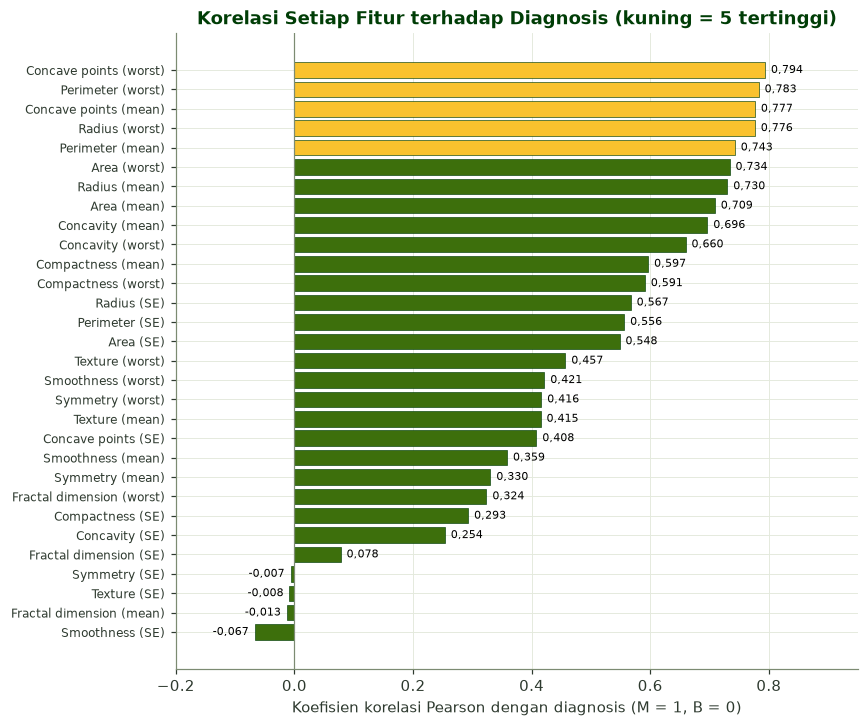

<p style='text-align:center'><b>Gambar 4.5</b> Korelasi Fitur terhadap Diagnosis<br><code>hasil_laporan/gambar/Gambar_4.5_Korelasi_Fitur_terhadap_Diagnosis.png</code></p>

In [15]:
kor = eda.korelasi_target(df).sort_values()
warna = [KUNING if v >= kor.nlargest(5).min() else HIJAU for v in kor.values]
fig, ax = plt.subplots(figsize=(8, 7.5))
ax.barh([prep.label_fitur(f) for f in kor.index], kor.values, color=warna, edgecolor=HIJAU_TUA, linewidth=0.4)
for i, v in enumerate(kor.values):
    ax.text(v + (0.01 if v >= 0 else -0.01), i, angka(v, 3), va="center", ha="left" if v >= 0 else "right", fontsize=7.5)
ax.axvline(0, color=ABU, linewidth=0.8); ax.set_xlim(-0.2, 0.95)
ax.tick_params(axis="y", labelsize=8); ax.set_xlabel("Koefisien korelasi Pearson dengan diagnosis (M = 1, B = 0)")
ax.set_title("Korelasi Setiap Fitur terhadap Diagnosis (kuning = 5 tertinggi)")
simpan_gambar(fig, "Gambar 4.5", "Korelasi Fitur terhadap Diagnosis")

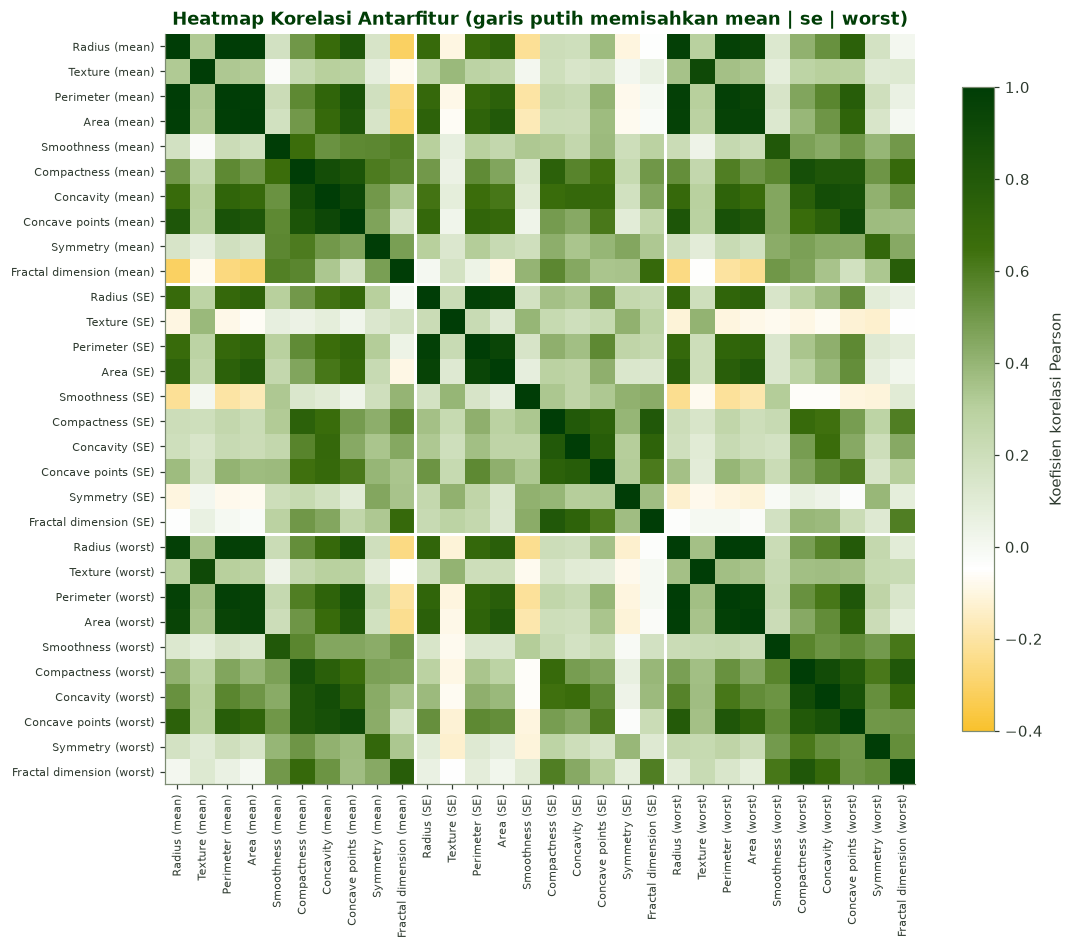

<p style='text-align:center'><b>Gambar 4.6</b> Heatmap Korelasi Antarfitur<br><code>hasil_laporan/gambar/Gambar_4.6_Heatmap_Korelasi_Antarfitur.png</code></p>

In [16]:
c = df[prep.FITUR].corr()
fig, ax = plt.subplots(figsize=(11, 9.5)); ax.grid(False)
im = ax.imshow(c.values, cmap=CMAP_KORELASI, vmin=-0.4, vmax=1)
lab = [prep.label_fitur(f) for f in prep.FITUR]
ax.set_xticks(range(30)); ax.set_xticklabels(lab, rotation=90, fontsize=7)
ax.set_yticks(range(30)); ax.set_yticklabels(lab, fontsize=7)
for k in (9.5, 19.5):
    ax.axhline(k, color="white", linewidth=2); ax.axvline(k, color="white", linewidth=2)
cb = fig.colorbar(im, ax=ax, shrink=0.8); cb.set_label("Koefisien korelasi Pearson")
ax.set_title("Heatmap Korelasi Antarfitur (garis putih memisahkan mean | se | worst)")
simpan_gambar(fig, "Gambar 4.6", "Heatmap Korelasi Antarfitur")

In [17]:
pk = eda.pasangan_korelasi_tinggi(df)
tab_pk = pd.DataFrame({"No": range(1, len(pk) + 1), "Fitur 1": pk["fitur_1"], "Fitur 2": pk["fitur_2"],
                       "Korelasi": [angka(v, 4) for v in pk["korelasi"]]})
tampil_tabel(tab_pk, "Tabel 4.5", "Pasangan Fitur dengan Korelasi Tinggi")
print(f"Jumlah pasangan dengan |korelasi| > 0,9: {len(pk)}")

<p style='text-align:center'><b>Tabel 4.5</b> Pasangan Fitur dengan Korelasi Tinggi</p>

No,Fitur 1,Fitur 2,Korelasi
1,radius_mean,perimeter_mean,"0,9979"
2,radius_worst,perimeter_worst,"0,9937"
3,radius_mean,area_mean,"0,9874"
4,perimeter_mean,area_mean,"0,9865"
5,radius_worst,area_worst,"0,9840"
6,perimeter_worst,area_worst,"0,9776"
7,radius_se,perimeter_se,"0,9728"
8,perimeter_mean,perimeter_worst,"0,9704"
9,radius_mean,radius_worst,"0,9695"
10,perimeter_mean,radius_worst,"0,9695"


`hasil_laporan/tabel/Tabel_4.5_Pasangan_Fitur_dengan_Korelasi_Tinggi.csv`

Jumlah pasangan dengan |korelasi| > 0,9: 21


## 4.3 Hasil *Data Preparation*

### 4.3.1 Hasil Penerapan *Preprocessing*
Langkah *preprocessing* ditentukan otomatis dari hasil EDA oleh `prep.rencana_preprocessing()`, lalu dijalankan oleh `prep.siapkan_data()`.

In [18]:
rencana = prep.rencana_preprocessing(hasil_eda)
siap = prep.siapkan_data(df, hasil_eda)
X, y = siap["X"], siap["y"]
X_latih, X_uji, y_latih, y_uji = siap["X_latih"], siap["X_uji"], siap["y_latih"], siap["y_uji"]
Xs_latih, Xs_uji, scaler = siap["Xs_latih"], siap["Xs_uji"], siap["scaler"]

tab_pre = pd.DataFrame({"Langkah": [r["langkah"] for r in rencana],
                        "Temuan EDA": [r["temuan"] for r in rencana],
                        "Hasil Penerapan": [r["tindakan"] for r in rencana]})
tab_pre = tab_pre[~tab_pre["Langkah"].isin(["Pembagian data", "Standardisasi fitur"])]   # dibahas di 4.3.2
tampil_tabel(tab_pre, "Tabel 4.6", "Hasil Penerapan Preprocessing Berdasarkan Temuan EDA")
print("Log preprocessing:")
for baris in siap["log"]:
    print(" -", baris)

<p style='text-align:center'><b>Tabel 4.6</b> Hasil Penerapan Preprocessing Berdasarkan Temuan EDA</p>

Langkah,Temuan EDA,Hasil Penerapan
Penanganan duplikat,0 baris duplikat,Tidak ada yang dihapus
Penanganan missing value,0 nilai kosong,Tidak perlu imputasi
Penanganan outlier,171 pasien memiliki outlier (IQR); 77.1% nilai outlier berasal dari malignant,Outlier dipertahankan (tidak dihapus)
Penghapusan kolom ID,Kolom id hanya nomor identitas pasien,Hapus kolom id
Transformasi label,"Label berupa huruf B, M","Malignant = 1, Benign = 0"
Seleksi fitur,"21 pasangan fitur berkorelasi > 0.9 (misalnya radius, perimeter, area)",Seluruh 30 fitur tetap digunakan


`hasil_laporan/tabel/Tabel_4.6_Hasil_Penerapan_Preprocessing_Berdasarkan_Temuan_EDA.csv`

Log preprocessing:
 - Duplikat: tidak ada, tidak ada baris yang dihapus
 - Outlier: 171 pasien memiliki outlier, dipertahankan
 - Kolom id dihapus; label diubah: Malignant = 1, Benign = 0
 - Seleksi fitur: tidak dilakukan, 30 fitur digunakan
 - Split stratified: 455 latih (37.4% malignant), 114 uji (36.8% malignant)
 - Missing value: tidak ada, tidak perlu imputasi
 - Standardisasi z-score: mu dan sigma dihitung dari data latih


### 4.3.2 Hasil Pembagian dan Standardisasi Data

In [19]:
def baris_split(nama, yy):
    yy = np.asarray(yy)
    return [nama, int((yy == 0).sum()), int((yy == 1).sum()), len(yy), angka(yy.mean() * 100, 1) + "%"]
tab_split = pd.DataFrame([baris_split("Data latih", y_latih), baris_split("Data uji", y_uji), baris_split("Total", y)],
                         columns=["Bagian", "Benign", "Malignant", "Total", "Persentase Malignant"])
tampil_tabel(tab_split, "Tabel 4.7", "Hasil Pembagian Data Latih dan Data Uji")

contoh = ["radius_mean", "texture_mean", "area_mean", "area_worst", "fractal_dimension_se"]
idx = [prep.FITUR.index(f) for f in contoh]
tab_z = pd.DataFrame({
    "Fitur": contoh,
    "μ (data latih)": [angka(scaler.mean_[i]) for i in idx],
    "σ (data latih)": [angka(scaler.scale_[i]) for i in idx],
    "Nilai asli": [angka(X_latih.iloc[0][f]) for f in contoh],
    "Nilai z-score": [angka(Xs_latih[0][i]) for i in idx],
})
tampil_tabel(tab_z, "Tabel 4.8", "Contoh Nilai Fitur Sebelum dan Sesudah Standardisasi")
print("Contoh diambil dari data pertama pada data latih.")

<p style='text-align:center'><b>Tabel 4.7</b> Hasil Pembagian Data Latih dan Data Uji</p>

Bagian,Benign,Malignant,Total,Persentase Malignant
Data latih,285,170,455,"37,4%"
Data uji,72,42,114,"36,8%"
Total,357,212,569,"37,3%"


`hasil_laporan/tabel/Tabel_4.7_Hasil_Pembagian_Data_Latih_dan_Data_Uji.csv`

<p style='text-align:center'><b>Tabel 4.8</b> Contoh Nilai Fitur Sebelum dan Sesudah Standardisasi</p>

Fitur,μ (data latih),σ (data latih),Nilai asli,Nilai z-score
radius_mean,"14,1264","3,6237","17,9900","1,0662"
texture_mean,"19,2581","4,3097","10,3800","-2,0600"
area_mean,"656,8358","362,3934","1.001,0000","0,9497"
area_worst,"880,0752","576,6410","2.019,0000","1,9751"
fractal_dimension_se,"0,0038","0,0027","0,0062","0,8705"


`hasil_laporan/tabel/Tabel_4.8_Contoh_Nilai_Fitur_Sebelum_dan_Sesudah_Standardisasi.csv`

Contoh diambil dari data pertama pada data latih.


## 4.4 Hasil *Modeling*
Kedua model dilatih pada 455 data latih dengan parameter yang sama seperti `train.py` (Subbab 3.5.1).

In [20]:
PARAM_RF = dict(n_estimators=100, max_depth=None, min_samples_split=2, max_features="sqrt", random_state=prep.RANDOM_STATE)
PARAM_SVM = dict(C=1.0, gamma="scale")

t = time.time(); rf = RandomForestManual(**PARAM_RF).fit(Xs_latih, y_latih); waktu_rf = time.time() - t
t = time.time(); svm = SVMManual(**PARAM_SVM, probability=True).fit(Xs_latih, y_latih); waktu_svm = time.time() - t

def info_pohon(node, d=0):
    if node["leaf"]:
        return d, 1, set()
    a = info_pohon(node["left"], d + 1); b = info_pohon(node["right"], d + 1)
    return max(a[0], b[0]), a[1] + b[1], a[2] | b[2] | {node["fitur"]}
info = [info_pohon(p) for p in rf.trees]
dalam = np.array([i[0] for i in info]); daun = np.array([i[1] for i in info])
fitur_dipakai = set().union(*[i[2] for i in info])

tab_rf = pd.DataFrame({
    "Hasil Pelatihan": ["Jumlah pohon terbentuk", "Kedalaman pohon (rata-rata; min–maks)",
                        "Jumlah simpul daun (rata-rata; min–maks)", "Fitur kandidat per simpul",
                        "Jumlah fitur yang pernah dipakai memisahkan simpul", "Waktu pelatihan"],
    "Nilai": [len(rf.trees), f"{angka(dalam.mean(), 1)}; {dalam.min()}–{dalam.max()}",
              f"{angka(daun.mean(), 1)}; {daun.min()}–{daun.max()}", f"{rf.m_features_} dari {rf.n_features_} fitur",
              f"{len(fitur_dipakai)} dari 30 fitur", f"{angka(waktu_rf, 2)} detik"],
})
tampil_tabel(tab_rf, "Tabel 4.9", "Hasil Pelatihan Random Forest")

sv_kelas = np.asarray(y_latih)[svm.support_]
tab_svm = pd.DataFrame({
    "Hasil Pelatihan": ["Nilai γ (scale)", "Jumlah support vector", "Support vector kelas Benign",
                        "Support vector kelas Malignant", "Bias b", "Jumlah iterasi SMO",
                        "Parameter sigmoid Platt (A; B)", "Waktu pelatihan"],
    "Nilai": [angka(svm.gamma_, 5), f"{svm.n_support_} dari {len(y_latih)} data latih",
              int((sv_kelas == 0).sum()), int((sv_kelas == 1).sum()), angka(svm.intercept_, 4), svm.n_iter_,
              f"{angka(svm.prob_a_, 4)}; {angka(svm.prob_b_, 4)}", f"{angka(waktu_svm, 2)} detik"],
})
tampil_tabel(tab_svm, "Tabel 4.10", "Hasil Pelatihan SVM")

<p style='text-align:center'><b>Tabel 4.9</b> Hasil Pelatihan Random Forest</p>

Hasil Pelatihan,Nilai
Jumlah pohon terbentuk,100
Kedalaman pohon (rata-rata; min–maks),"6,7; 5–9"
Jumlah simpul daun (rata-rata; min–maks),"16,4; 10–23"
Fitur kandidat per simpul,5 dari 30 fitur
Jumlah fitur yang pernah dipakai memisahkan simpul,30 dari 30 fitur
Waktu pelatihan,"0,42 detik"


`hasil_laporan/tabel/Tabel_4.9_Hasil_Pelatihan_Random_Forest.csv`

<p style='text-align:center'><b>Tabel 4.10</b> Hasil Pelatihan SVM</p>

Hasil Pelatihan,Nilai
Nilai γ (scale),"0,03333"
Jumlah support vector,101 dari 455 data latih
Support vector kelas Benign,49
Support vector kelas Malignant,52
Bias b,"0,2646"
Jumlah iterasi SMO,272
Parameter sigmoid Platt (A; B),"-3,6996; -0,3165"
Waktu pelatihan,"0,05 detik"


`hasil_laporan/tabel/Tabel_4.10_Hasil_Pelatihan_SVM.csv`

## 4.5 Hasil *Evaluation*

### 4.5.1 Hasil *Confusion Matrix* Data Uji
Sel hijau tua = prediksi benar, sel kuning = *False Negative* (paling berbahaya secara medis), sel hijau muda = *False Positive*.

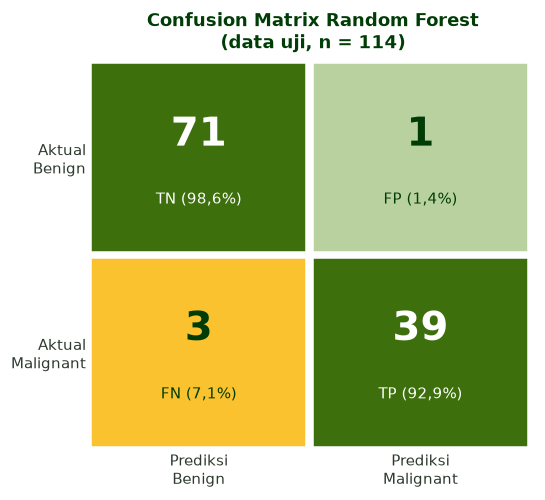

<p style='text-align:center'><b>Gambar 4.7</b> Confusion Matrix Random Forest<br><code>hasil_laporan/gambar/Gambar_4.7_Confusion_Matrix_Random_Forest.png</code></p>

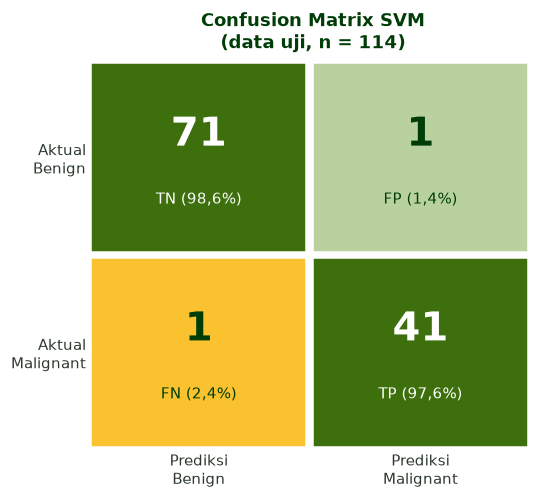

<p style='text-align:center'><b>Gambar 4.8</b> Confusion Matrix SVM<br><code>hasil_laporan/gambar/Gambar_4.8_Confusion_Matrix_SVM.png</code></p>

<p style='text-align:center'><b>Tabel 4.11</b> Hasil Metrik Evaluasi pada Data Uji</p>

Model,Accuracy,Precision,Recall,F1-Score,TP,TN,FP,FN
Random Forest,"96,49%","97,50%","92,86%","95,12%",39,71,1,3
SVM,"98,25%","97,62%","97,62%","97,62%",41,71,1,1


`hasil_laporan/tabel/Tabel_4.11_Hasil_Metrik_Evaluasi_pada_Data_Uji.csv`

In [21]:
def gambar_cm(m, judul):
    fig, ax = plt.subplots(figsize=(5.2, 4.6)); ax.grid(False)
    sel = [[("TN", m["TN"], HIJAU, "white"), ("FP", m["FP"], HIJAU_MUDA, HIJAU_TUA)],
           [("FN", m["FN"], KUNING, HIJAU_TUA), ("TP", m["TP"], HIJAU, "white")]]
    total_baris = [m["TN"] + m["FP"], m["FN"] + m["TP"]]
    for i in range(2):
        for j in range(2):
            kode, n, w, c = sel[i][j]
            ax.add_patch(plt.Rectangle((j, 1 - i), 0.97, 0.97, facecolor=w, edgecolor="white"))
            ax.text(j + 0.485, 1 - i + 0.6, str(n), ha="center", va="center", fontsize=26, fontweight="bold", color=c)
            ax.text(j + 0.485, 1 - i + 0.27, f"{kode} ({angka(n / total_baris[i] * 100, 1)}%)", ha="center", va="center",
                    fontsize=10, color=c)
    ax.set_xlim(0, 2); ax.set_ylim(0, 2)
    ax.set_xticks([0.485, 1.485]); ax.set_xticklabels(["Prediksi\nBenign", "Prediksi\nMalignant"])
    ax.set_yticks([1.485, 0.485]); ax.set_yticklabels(["Aktual\nBenign", "Aktual\nMalignant"])
    ax.spines[["left", "bottom"]].set_visible(False); ax.tick_params(length=0)
    ax.set_title(judul)
    return fig

hasil_holdout = {}
for nama, model, nomor in [("Random Forest", rf, "Gambar 4.7"), ("SVM", svm, "Gambar 4.8")]:
    m = ev.hitung_metrik(y_uji, model.predict(Xs_uji)); hasil_holdout[nama] = m
    fig = gambar_cm(m, f"Confusion Matrix {nama}\n(data uji, n = {len(y_uji)})")
    simpan_gambar(fig, nomor, f"Confusion Matrix {nama}")

tab_hold = pd.DataFrame([[n, persen(m["accuracy"]), persen(m["precision"]), persen(m["recall"]), persen(m["f1_score"]),
                          m["TP"], m["TN"], m["FP"], m["FN"]] for n, m in hasil_holdout.items()],
                        columns=["Model", "Accuracy", "Precision", "Recall", "F1-Score", "TP", "TN", "FP", "FN"])
tampil_tabel(tab_hold, "Tabel 4.11", "Hasil Metrik Evaluasi pada Data Uji")

### 4.5.2 Hasil *Stratified* 10-*Fold Cross Validation*
Proses ini menjalankan 50 pengujian per model (± 35 detik). *Imputer* dan *scaler* di-*fit* ulang di setiap *fold*.

In [22]:
hasil_kfold = ev.validasi_kfold({"Random Forest": lambda: RandomForestManual(**PARAM_RF),
                                 "SVM": lambda: SVMManual(**PARAM_SVM)}, X, y)
ringkasan = ev.ringkas_kfold(hasil_kfold)
hasil_kfold.to_csv(OUT / "tabel" / "Lampiran_Hasil_50_Pengujian_KFold.csv", index=False)

METRIK = [("accuracy", "Accuracy"), ("precision", "Precision"), ("recall", "Recall"), ("f1_score", "F1-Score")]
tab_kf = pd.DataFrame([[r["model"]] + [f"{persen(r[k + '_mean'])} ± {persen(r[k + '_std'])}" for k, _ in METRIK]
                       for _, r in ringkasan.iterrows()], columns=["Model"] + [n for _, n in METRIK])
tampil_tabel(tab_kf, "Tabel 4.12", "Hasil Stratified 10-Fold Cross Validation × 5")

g = hasil_kfold.groupby("model")
total = g[["TP", "TN", "FP", "FN"]].sum()
print("Ringkasan 50 pengujian:")
for nama in total.index:
    s = g.get_group(nama)
    print(f"  {nama:<13} FN total {total.loc[nama, 'FN']:>3} dari {total.loc[nama, 'TP'] + total.loc[nama, 'FN']} prediksi malignant | "
          f"FP total {total.loc[nama, 'FP']:>3} | recall terendah {persen(s['recall'].min())} | recall = 100% pada {(s['recall'] == 1).sum()} pengujian")
w = hasil_kfold.pivot_table(index=["ulangan", "fold"], columns="model", values="recall")
print(f"  Recall SVM vs RF per pengujian: lebih tinggi {(w['SVM'] > w['Random Forest']).sum()}, "
      f"sama {(w['SVM'] == w['Random Forest']).sum()}, lebih rendah {(w['SVM'] < w['Random Forest']).sum()}")

  ulangan 1/5 selesai (6 detik)


  ulangan 2/5 selesai (13 detik)


  ulangan 3/5 selesai (18 detik)


  ulangan 4/5 selesai (25 detik)


  ulangan 5/5 selesai (31 detik)


<p style='text-align:center'><b>Tabel 4.12</b> Hasil Stratified 10-Fold Cross Validation × 5</p>

Model,Accuracy,Precision,Recall,F1-Score
Random Forest,"96,06% ± 3,03%","95,81% ± 4,66%","93,67% ± 5,56%","94,62% ± 4,17%"
SVM,"97,64% ± 1,97%","97,58% ± 3,12%","96,13% ± 3,40%","96,81% ± 2,63%"


`hasil_laporan/tabel/Tabel_4.12_Hasil_Stratified_10_Fold_Cross_Validation_5.csv`

Ringkasan 50 pengujian:
  Random Forest FN total  67 dari 1060 prediksi malignant | FP total  45 | recall terendah 76,19% | recall = 100% pada 11 pengujian
  SVM           FN total  41 dari 1060 prediksi malignant | FP total  26 | recall terendah 90,48% | recall = 100% pada 18 pengujian
  Recall SVM vs RF per pengujian: lebih tinggi 24, sama 20, lebih rendah 6


### 4.5.3 Hasil Perbandingan Kinerja dan Model Terbaik
Model terbaik dipilih dengan aturan Subbab 3.6.3: *recall* rata-rata tertinggi; jika selisihnya ≤ 0,01 poin persen, dibandingkan *F1-score*.

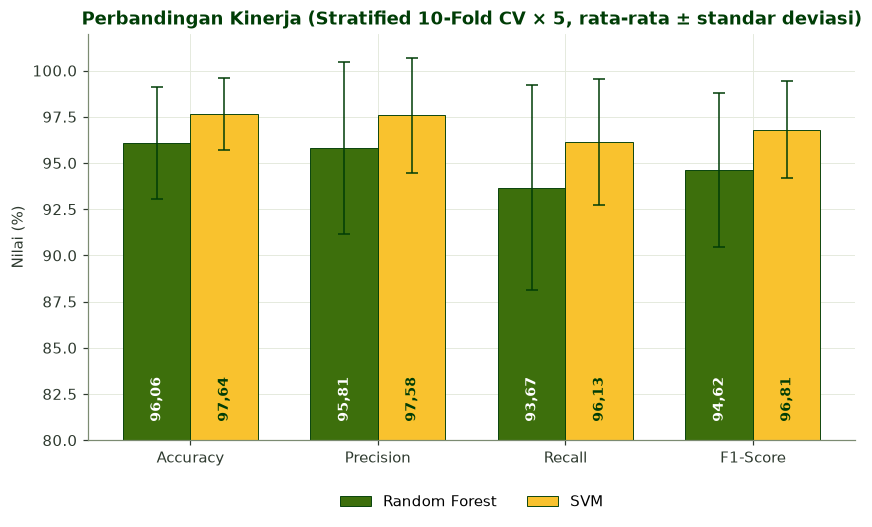

<p style='text-align:center'><b>Gambar 4.9</b> Grafik Perbandingan Metrik Random Forest dan SVM<br><code>hasil_laporan/gambar/Gambar_4.9_Grafik_Perbandingan_Metrik_Random_Forest_dan_SVM.png</code></p>

<div style='background:#F1F5EC;border-left:8px solid #F9C22E;padding:10px 14px'><b>Model terbaik: SVM</b><br>Recall rata-rata SVM lebih tinggi (96.13% vs 93.67%).</div>

In [23]:
fig, ax = plt.subplots(figsize=(9, 4.8))
xpos = np.arange(4); lebar = 0.36
for k, (nama, warna) in enumerate(WARNA_MODEL.items()):
    r = ringkasan.set_index("model").loc[nama]
    mean = [r[m + "_mean"] * 100 for m, _ in METRIK]; std = [r[m + "_std"] * 100 for m, _ in METRIK]
    b = ax.bar(xpos + (k - 0.5) * lebar, mean, lebar, yerr=std, capsize=4, color=warna, edgecolor=HIJAU_TUA,
               linewidth=0.6, label=nama, error_kw=dict(ecolor=HIJAU_TUA, elinewidth=1))
    for bb, v in zip(b, mean):
        ax.text(bb.get_x() + bb.get_width() / 2, 81, angka(v, 2), ha="center", va="bottom", rotation=90,
                fontsize=9, fontweight="bold", color="white" if warna == HIJAU else HIJAU_TUA)
ax.set_xticks(xpos); ax.set_xticklabels([n for _, n in METRIK]); ax.set_ylim(80, 102)
ax.set_ylabel("Nilai (%)"); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
ax.set_title("Perbandingan Kinerja (Stratified 10-Fold CV × 5, rata-rata ± standar deviasi)")
simpan_gambar(fig, "Gambar 4.9", "Grafik Perbandingan Metrik Random Forest dan SVM")

terbaik = ev.pilih_model_terbaik(ringkasan)
display(Markdown(f"<div style='background:{KREM};border-left:8px solid {KUNING};padding:10px 14px'>"
                 f"<b>Model terbaik: {terbaik['model']}</b><br>{terbaik['alasan']}</div>"))

### 4.5.4 Hasil Interpretasi Model

#### 4.5.4.1 Hasil *Feature Importance Random Forest*
Dihitung dengan `random_forest/feature_importance.py` (penurunan *entropy* / *Information Gain*).

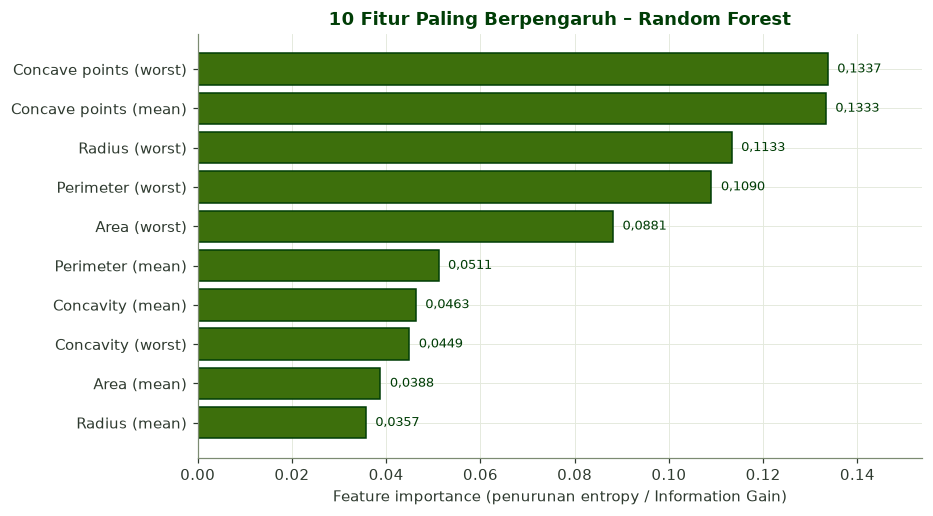

<p style='text-align:center'><b>Gambar 4.10</b> Sepuluh Fitur dengan Feature Importance Tertinggi<br><code>hasil_laporan/gambar/Gambar_4.10_Sepuluh_Fitur_dengan_Feature_Importance_Tertinggi.png</code></p>

<p style='text-align:center'><b>Tabel 4.13</b> Peringkat Feature Importance Random Forest</p>

Peringkat,Fitur,Feature Importance
1,concave_points_worst,"0,1337"
2,concave_points_mean,"0,1333"
3,radius_worst,"0,1133"
4,perimeter_worst,"0,1090"
5,area_worst,"0,0881"
6,perimeter_mean,"0,0511"
7,concavity_mean,"0,0463"
8,concavity_worst,"0,0449"
9,area_mean,"0,0388"
10,radius_mean,"0,0357"


`hasil_laporan/tabel/Tabel_4.13_Peringkat_Feature_Importance_Random_Forest.csv` (ditampilkan 10 dari 30 baris, CSV berisi semua baris)

Kontribusi 5 fitur teratas : 57,8%
Kontribusi 10 fitur teratas: 79,4%


In [24]:
tabel_fi = fi.tabel_feature_importance(rf)
top = tabel_fi.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.barh(top["nama"], top["importance"], color=HIJAU, edgecolor=HIJAU_TUA)
for i, v in enumerate(top["importance"]):
    ax.text(v + 0.002, i, angka(v, 4), va="center", fontsize=8.5, color=HIJAU_TUA)
ax.set_xlim(0, top["importance"].max() * 1.15)
ax.set_xlabel("Feature importance (penurunan entropy / Information Gain)")
ax.set_title("10 Fitur Paling Berpengaruh – Random Forest")
simpan_gambar(fig, "Gambar 4.10", "Sepuluh Fitur dengan Feature Importance Tertinggi")

tab_fi = pd.DataFrame({"Peringkat": tabel_fi["peringkat"], "Fitur": tabel_fi["fitur"],
                       "Feature Importance": [angka(v, 4) for v in tabel_fi["importance"]]})
tampil_tabel(tab_fi, "Tabel 4.13", "Peringkat Feature Importance Random Forest", tampil=10)
print(f"Kontribusi 5 fitur teratas : {persen(tabel_fi['importance'].head(5).sum(), 1)}")
print(f"Kontribusi 10 fitur teratas: {persen(tabel_fi['importance'].head(10).sum(), 1)}")

#### 4.5.4.2 Hasil SHAP Global SVM
SHAP dihitung untuk seluruh 114 data uji (`nsamples = 1000`, *background* 20 titik *k-means*). Pada *summary plot*, warna **kuning = nilai fitur tinggi** dan **hijau = nilai fitur rendah**; titik di kanan nol mendorong prediksi ke *malignant*.

SHAP global selesai dalam 3 detik | nilai awal (φ0) = 0,3505


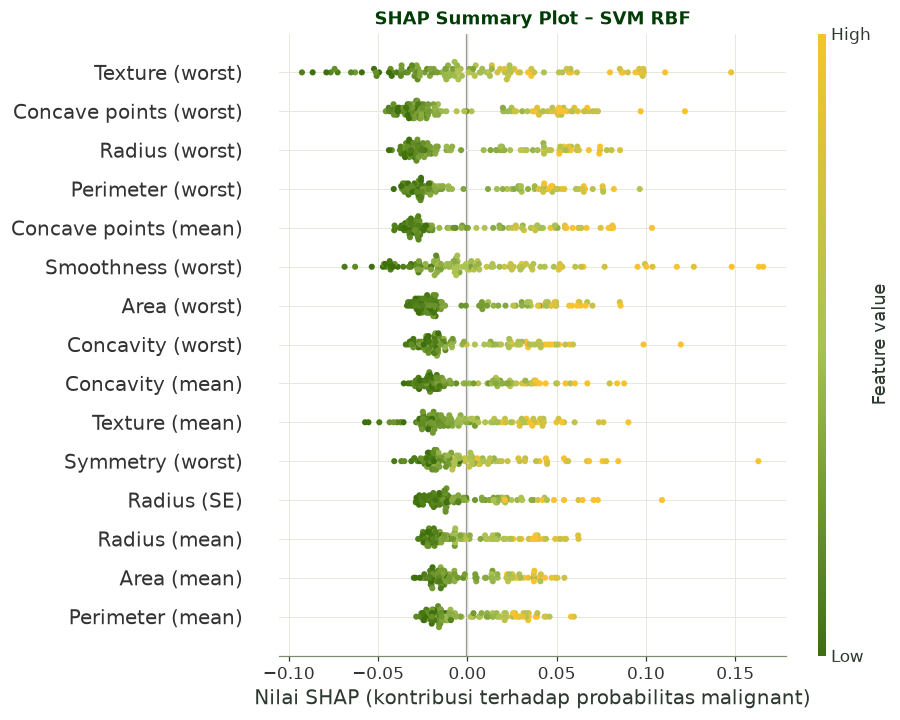

<p style='text-align:center'><b>Gambar 4.11</b> SHAP Summary Plot SVM<br><code>hasil_laporan/gambar/Gambar_4.11_SHAP_Summary_Plot_SVM.png</code></p>

In [25]:
background = shap_svm.buat_background(Xs_latih)
explainer = shap_svm.buat_explainer(svm, background)
t = time.time()
matriks_shap = shap_svm.jelaskan_global(explainer, Xs_uji, nsamples=1000)
ranking = shap_svm.ranking_global(matriks_shap)
base_value = float(np.asarray(explainer.expected_value).reshape(-1)[0])
print(f"SHAP global selesai dalam {time.time() - t:.0f} detik | nilai awal (φ0) = {angka(base_value, 4)}")

shap.summary_plot(matriks_shap, X_uji.to_numpy(), feature_names=[prep.label_fitur(f) for f in prep.FITUR],
                  max_display=15, cmap=CMAP_SHAP, show=False, plot_size=(8.5, 6.5))
fig = plt.gcf(); ax = plt.gca()
ax.set_xlabel("Nilai SHAP (kontribusi terhadap probabilitas malignant)")
ax.set_title("SHAP Summary Plot – SVM RBF", color=HIJAU_TUA, fontweight="bold")
simpan_gambar(fig, "Gambar 4.11", "SHAP Summary Plot SVM")

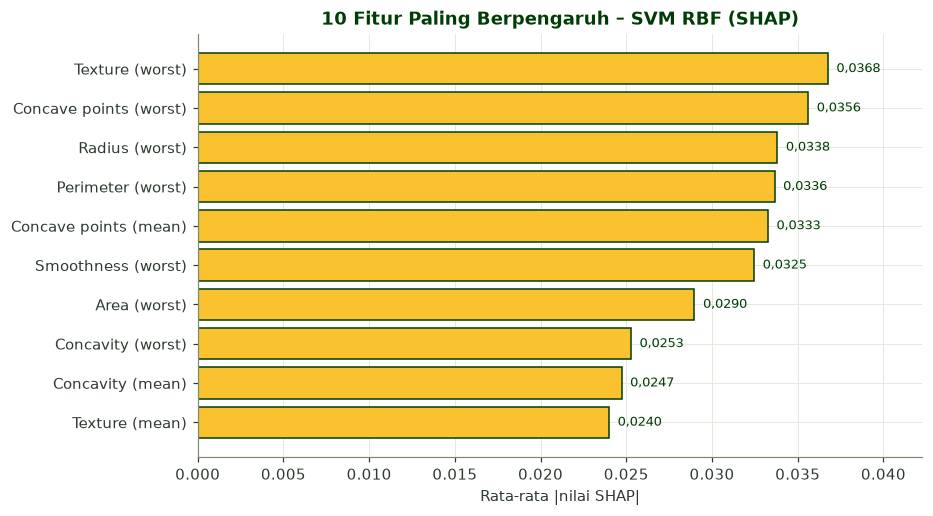

<p style='text-align:center'><b>Gambar 4.12</b> Rata-rata Nilai SHAP per Fitur<br><code>hasil_laporan/gambar/Gambar_4.12_Rata_rata_Nilai_SHAP_per_Fitur.png</code></p>

<p style='text-align:center'><b>Tabel 4.14</b> Peringkat Fitur Berdasarkan Nilai SHAP</p>

Peringkat,Fitur,Rata-rata |SHAP|
1,texture_worst,"0,0368"
2,concave_points_worst,"0,0356"
3,radius_worst,"0,0338"
4,perimeter_worst,"0,0336"
5,concave_points_mean,"0,0333"
6,smoothness_worst,"0,0325"
7,area_worst,"0,0290"
8,concavity_worst,"0,0253"
9,concavity_mean,"0,0247"
10,texture_mean,"0,0240"


`hasil_laporan/tabel/Tabel_4.14_Peringkat_Fitur_Berdasarkan_Nilai_SHAP.csv` (ditampilkan 10 dari 30 baris, CSV berisi semua baris)

In [26]:
top = ranking.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.barh(top["nama"], top["mean_abs_shap"], color=KUNING, edgecolor=HIJAU_TUA)
for i, v in enumerate(top["mean_abs_shap"]):
    ax.text(v + 0.0005, i, angka(v, 4), va="center", fontsize=8.5, color=HIJAU_TUA)
ax.set_xlim(0, top["mean_abs_shap"].max() * 1.15)
ax.set_xlabel("Rata-rata |nilai SHAP|")
ax.set_title("10 Fitur Paling Berpengaruh – SVM RBF (SHAP)")
simpan_gambar(fig, "Gambar 4.12", "Rata-rata Nilai SHAP per Fitur")

tab_sh = pd.DataFrame({"Peringkat": ranking["peringkat"], "Fitur": ranking["fitur"],
                       "Rata-rata |SHAP|": [angka(v, 4) for v in ranking["mean_abs_shap"]]})
tampil_tabel(tab_sh, "Tabel 4.14", "Peringkat Fitur Berdasarkan Nilai SHAP", tampil=10)

#### 4.5.4.3 Hasil SHAP Lokal
Contoh penjelasan untuk satu pasien *malignant* (pasien *malignant* pertama pada data uji), sama seperti yang muncul di aplikasi setiap kali tenaga medis melakukan prediksi.

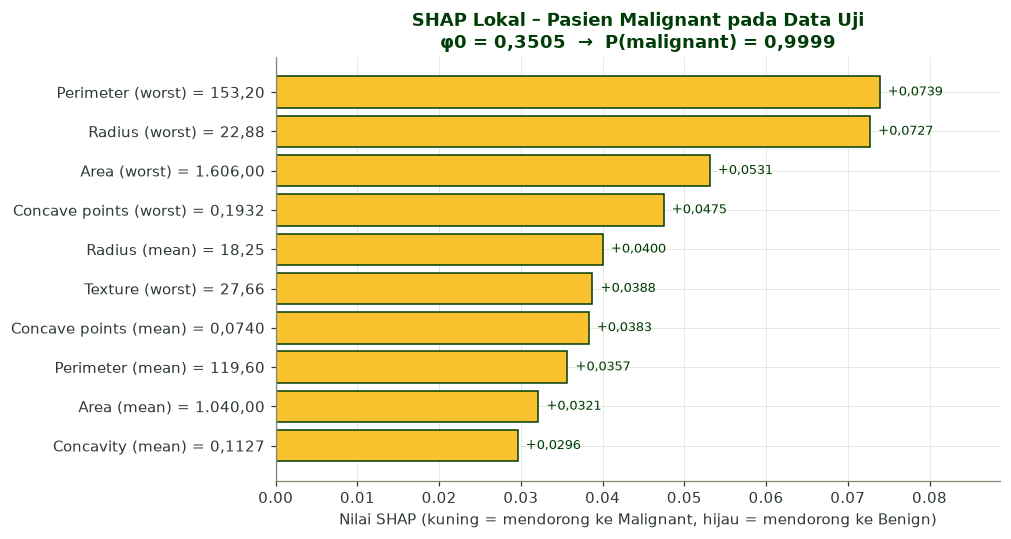

<p style='text-align:center'><b>Gambar 4.13</b> Penjelasan SHAP Lokal pada Satu Pasien Malignant<br><code>hasil_laporan/gambar/Gambar_4.13_Penjelasan_SHAP_Lokal_pada_Satu_Pasien_Malignant.png</code></p>

Local accuracy (φ0 + Σφ = f(x)): True


In [27]:
i_pasien = int(np.flatnonzero(np.asarray(y_uji) == 1)[0])
lokal = shap_svm.jelaskan_lokal(explainer, Xs_uji[i_pasien])
tl = pd.DataFrame({"fitur": prep.FITUR, "nilai": X_uji.iloc[i_pasien].to_numpy(), "shap": lokal["shap"]})
tl = tl.reindex(tl["shap"].abs().sort_values(ascending=False).index).head(10).iloc[::-1]

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.barh([f"{prep.label_fitur(f)} = {angka(v, 4 if abs(v) < 1 else 2)}" for f, v in zip(tl["fitur"], tl["nilai"])],
        tl["shap"], color=[KUNING if s > 0 else HIJAU for s in tl["shap"]], edgecolor=HIJAU_TUA)
for i, s in enumerate(tl["shap"]):
    ax.text(s + (0.001 if s > 0 else -0.001), i, f"{'+' if s > 0 else ''}{angka(s, 4)}", va="center",
            ha="left" if s > 0 else "right", fontsize=8.5, color=HIJAU_TUA)
ax.axvline(0, color=ABU, linewidth=0.8)
ax.set_xlim(min(0, tl["shap"].min()) * 1.2, tl["shap"].max() * 1.2)
ax.set_xlabel("Nilai SHAP (kuning = mendorong ke Malignant, hijau = mendorong ke Benign)")
ax.set_title(f"SHAP Lokal – Pasien Malignant pada Data Uji\nφ0 = {angka(lokal['base_value'], 4)}  →  "
             f"P(malignant) = {angka(lokal['prediksi'], 4)}")
simpan_gambar(fig, "Gambar 4.13", "Penjelasan SHAP Lokal pada Satu Pasien Malignant")
print(f"Local accuracy (φ0 + Σφ = f(x)): {lokal['local_accuracy']}")

## 4.6 Hasil *Deployment*

### 4.6.1 Implementasi Basis Data
Struktur tabel dibaca langsung dari basis data SQLite yang dibuat oleh `basis_data/database.py`.

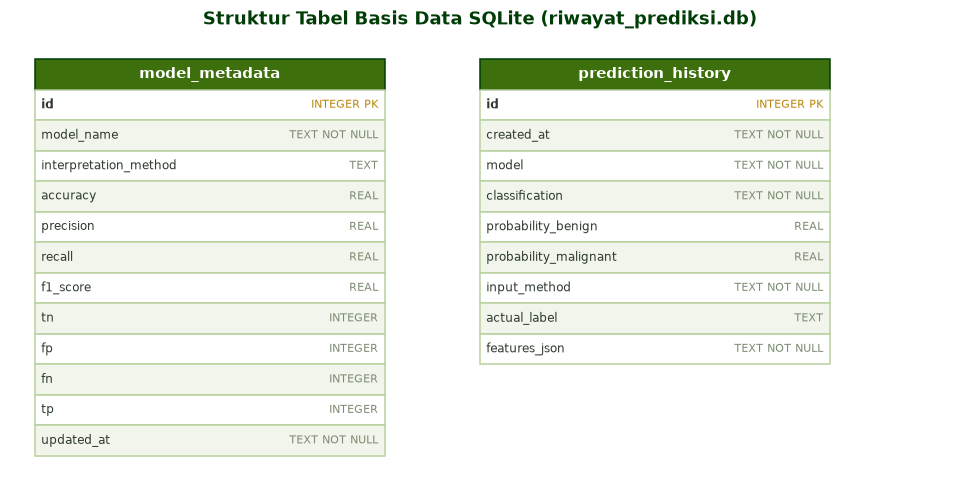

<p style='text-align:center'><b>Gambar 4.14</b> Struktur Tabel Basis Data SQLite<br><code>hasil_laporan/gambar/Gambar_4.14_Struktur_Tabel_Basis_Data_SQLite.png</code></p>

In [28]:
# Struktur tabel dibaca langsung dari basis data SQLite buatan basis_data/database.py
DB_SKEMA = Path("hasil_laporan") / "skema_basis_data.db"
db.inisialisasi_database(DB_SKEMA)
with sqlite3.connect(DB_SKEMA) as con:
    nama_tabel = [r[0] for r in con.execute("SELECT name FROM sqlite_master WHERE type='table' AND name NOT LIKE 'sqlite_%' ORDER BY name")]
    skema = {t: con.execute(f"PRAGMA table_info({t})").fetchall() for t in nama_tabel}

fig, ax = plt.subplots(figsize=(11, 5.2)); ax.axis("off"); ax.grid(False)
lebar_t, h = 4.4, 0.36
maks = max(len(v) for v in skema.values())
ax.set_xlim(0, 0.6 + (lebar_t + 1.2) * len(skema)); ax.set_ylim(-h * (maks + 1.6), 0.3)
for n, (tabel, kolom) in enumerate(skema.items()):
    x0 = 0.3 + n * (lebar_t + 1.2)
    ax.add_patch(plt.Rectangle((x0, -h), lebar_t, h, facecolor=HIJAU, edgecolor=HIJAU_TUA))
    ax.text(x0 + lebar_t / 2, -h / 2, tabel, ha="center", va="center", color="white", fontweight="bold")
    for k, (_, nama, tipe, notnull, _, pk) in enumerate(kolom):
        yy = -h * (k + 2)
        ax.add_patch(plt.Rectangle((x0, yy), lebar_t, h, facecolor=KREM if k % 2 else "white", edgecolor=HIJAU_MUDA))
        ax.text(x0 + 0.08, yy + h / 2, nama, va="center", fontsize=8, color=TEKS, fontweight="bold" if pk else "normal")
        ket = (tipe + (" PK" if pk else "") + (" NOT NULL" if notnull and not pk else "")).strip()
        ax.text(x0 + lebar_t - 0.08, yy + h / 2, ket, va="center", ha="right", fontsize=7.5, color=KUNING_TUA if pk else ABU)
ax.set_title("Struktur Tabel Basis Data SQLite (riwayat_prediksi.db)")
simpan_gambar(fig, "Gambar 4.14", "Struktur Tabel Basis Data SQLite")


### 4.6.2 Implementasi Antarmuka
Gambar 4.15–4.20 berupa *screenshot* aplikasi, **tidak** dibuat oleh notebook ini. Jalankan `streamlit run app.py`, lalu ambil *screenshot*:

| Gambar | Halaman |
|---|---|
| 4.15 | Prediksi – Input Manual |
| 4.16 | Prediksi – Unggah CSV |
| 4.17 | Hasil Prediksi dan Penjelasan SHAP |
| 4.18 | Riwayat Prediksi |
| 4.19 | Evaluasi Model |
| 4.20 | Tentang Data |

### 4.6.3 Hasil *Blackbox Testing*
Templat tabel. Kolom **Hasil Pengujian** dan **Status** diisi setelah pengujian aplikasi dilakukan (Tabel 3.5 untuk skenario lengkapnya).

In [29]:
blackbox = pd.DataFrame({
    "Kode": [f"F-{i:02d}" for i in range(1, 12)],
    "Kebutuhan yang Diuji": ["Menampilkan informasi dataset, EDA, dan keputusan preprocessing",
                             "Menerima masukan 30 fitur untuk satu pasien",
                             "Mengisi masukan otomatis dari data pasien pada dataset",
                             "Menerima masukan banyak pasien melalui file CSV",
                             "Memvalidasi data masukan",
                             "Melakukan prediksi menggunakan Random Forest dan SVM",
                             "Menampilkan label, probabilitas, dan unduh hasil CSV",
                             "Menampilkan penjelasan SHAP satu pasien",
                             "Menyimpan dan menampilkan riwayat prediksi",
                             "Menampilkan evaluasi model",
                             "Menampilkan SHAP global (summary plot)"],
    "Hasil Pengujian": ["(diisi setelah pengujian)"] * 11,
    "Status": ["(Berhasil / Gagal)"] * 11,
})
tampil_tabel(blackbox, "Tabel 4.15", "Hasil Pengujian Blackbox Testing")

<p style='text-align:center'><b>Tabel 4.15</b> Hasil Pengujian Blackbox Testing</p>

Kode,Kebutuhan yang Diuji,Hasil Pengujian,Status
F-01,"Menampilkan informasi dataset, EDA, dan keputusan preprocessing",(diisi setelah pengujian),(Berhasil / Gagal)
F-02,Menerima masukan 30 fitur untuk satu pasien,(diisi setelah pengujian),(Berhasil / Gagal)
F-03,Mengisi masukan otomatis dari data pasien pada dataset,(diisi setelah pengujian),(Berhasil / Gagal)
F-04,Menerima masukan banyak pasien melalui file CSV,(diisi setelah pengujian),(Berhasil / Gagal)
F-05,Memvalidasi data masukan,(diisi setelah pengujian),(Berhasil / Gagal)
F-06,Melakukan prediksi menggunakan Random Forest dan SVM,(diisi setelah pengujian),(Berhasil / Gagal)
F-07,"Menampilkan label, probabilitas, dan unduh hasil CSV",(diisi setelah pengujian),(Berhasil / Gagal)
F-08,Menampilkan penjelasan SHAP satu pasien,(diisi setelah pengujian),(Berhasil / Gagal)
F-09,Menyimpan dan menampilkan riwayat prediksi,(diisi setelah pengujian),(Berhasil / Gagal)
F-10,Menampilkan evaluasi model,(diisi setelah pengujian),(Berhasil / Gagal)


`hasil_laporan/tabel/Tabel_4.15_Hasil_Pengujian_Blackbox_Testing.csv`

## 4.7 Pembahasan

### 4.7.4 Perbandingan dengan Penelitian Terdahulu
Baris "Penelitian ini" diisi otomatis dari hasil *K-Fold* di atas.

In [30]:
r_svm = ringkasan.set_index("model").loc["SVM"]; r_rf = ringkasan.set_index("model").loc["Random Forest"]
pembanding = pd.DataFrame({
    "Penelitian": ["Raha dkk. (2024)", "Zhou dkk. (2024)", "Strelcenia dan Prakoonwit (2023)", "Penelitian ini"],
    "Metode dan Validasi": ["RF, XGBoost, GB, SVM, MLP; grid search; hold-out 67 : 33",
                            "7 algoritma; 8 fitur hasil seleksi; hold-out 80 : 20",
                            "6 algoritma dengan feature engineering",
                            "RF dan SVM; 30 fitur; Stratified 10-Fold × 5 (50 pengujian)"],
    "Hasil Terbaik": ["RF, accuracy 99,46%", "AdaBoost-Logistic, accuracy 99,12%; RF dan SVM 97,37%",
                      "Decision Tree, accuracy 98,64%",
                      f"SVM, accuracy {persen(r_svm['accuracy_mean'])} ± {persen(r_svm['accuracy_std'])}, recall {persen(r_svm['recall_mean'])} "
                      f"(RF {persen(r_rf['accuracy_mean'])})"],
    "Fitur Paling Berpengaruh": ["worst perimeter, worst area, worst concave points, worst radius, mean concave points (SHAP pada RF)",
                                 "8 fitur dengan korelasi > 0,7 terhadap diagnosis", "Tidak menggunakan XAI",
                                 f"RF: {', '.join(tabel_fi['fitur'].head(3))}; SVM (SHAP): {', '.join(ranking['fitur'].head(3))}"],
})
tampil_tabel(pembanding, "Tabel 4.16", "Perbandingan dengan Penelitian Terdahulu")

<p style='text-align:center'><b>Tabel 4.16</b> Perbandingan dengan Penelitian Terdahulu</p>

Penelitian,Metode dan Validasi,Hasil Terbaik,Fitur Paling Berpengaruh
Raha dkk. (2024),"RF, XGBoost, GB, SVM, MLP; grid search; hold-out 67 : 33","RF, accuracy 99,46%","worst perimeter, worst area, worst concave points, worst radius, mean concave points (SHAP pada RF)"
Zhou dkk. (2024),7 algoritma; 8 fitur hasil seleksi; hold-out 80 : 20,"AdaBoost-Logistic, accuracy 99,12%; RF dan SVM 97,37%","8 fitur dengan korelasi > 0,7 terhadap diagnosis"
Strelcenia dan Prakoonwit (2023),6 algoritma dengan feature engineering,"Decision Tree, accuracy 98,64%",Tidak menggunakan XAI
Penelitian ini,RF dan SVM; 30 fitur; Stratified 10-Fold × 5 (50 pengujian),"SVM, accuracy 97,64% ± 1,97%, recall 96,13% (RF 96,06%)","RF: concave_points_worst, concave_points_mean, radius_worst; SVM (SHAP): texture_worst, concave_points_worst, radius_worst"


`hasil_laporan/tabel/Tabel_4.16_Perbandingan_dengan_Penelitian_Terdahulu.csv`

---
## Daftar File yang Dihasilkan

In [31]:
gb = sorted((OUT / "gambar").glob("*.png")); tb = sorted((OUT / "tabel").glob("*.csv"))
print(f"{len(gb)} gambar di {OUT / 'gambar'}:")
for f in gb: print("  ", f.name)
print(f"\n{len(tb)} tabel di {OUT / 'tabel'}:")
for f in tb: print("  ", f.name)

17 gambar di hasil_laporan/gambar:
   Gambar_3.x_Alur_Data_Preparation.png
   Gambar_3.x_Alur_Tahapan_Penelitian_CRISP_DM.png
   Gambar_3.x_Skema_Stratified_10_Fold_Cross_Validation.png
   Gambar_4.10_Sepuluh_Fitur_dengan_Feature_Importance_Tertinggi.png
   Gambar_4.11_SHAP_Summary_Plot_SVM.png
   Gambar_4.12_Rata_rata_Nilai_SHAP_per_Fitur.png
   Gambar_4.13_Penjelasan_SHAP_Lokal_pada_Satu_Pasien_Malignant.png
   Gambar_4.14_Struktur_Tabel_Basis_Data_SQLite.png
   Gambar_4.1_Distribusi_Kelas_Malignant_dan_Benign.png
   Gambar_4.2_Perbandingan_Skala_Fitur.png
   Gambar_4.3_Histogram_Fitur_Mean.png
   Gambar_4.4_Boxplot_Outlier_per_Kelas.png
   Gambar_4.5_Korelasi_Fitur_terhadap_Diagnosis.png
   Gambar_4.6_Heatmap_Korelasi_Antarfitur.png
   Gambar_4.7_Confusion_Matrix_Random_Forest.png
   Gambar_4.8_Confusion_Matrix_SVM.png
   Gambar_4.9_Grafik_Perbandingan_Metrik_Random_Forest_dan_SVM.png

19 tabel di hasil_laporan/tabel:
   Lampiran_Hasil_50_Pengujian_KFold.csv
   Tabel_3.x_Deskripsi_F